In [2]:
import os
import glob
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models, Input, mixed_precision
from sklearn.model_selection import train_test_split
import cv2
import keras
print("library loaded successfully")
print("*"*100)

library loaded successfully
****************************************************************************************************


In [3]:
IMG_SIZE = 256  # Standardized input resolution for both phases
BATCH_SIZE = 4 # Batch size
EPOCHS_PHASE1 = 150  # Semantic Segmentation Focus, for Segmentation 

In [4]:
# Directory and Artifact Paths
DATA_PATH = '/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2'
POSITIVE_DIR = os.path.join(DATA_PATH, 'imagesAll_positive') # For Polyp classification
NEGATIVE_DIR = os.path.join(DATA_PATH, 'sequenceData/negativeOnly')  # For non polyp classification
MODEL_SAVE_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras"

In [5]:
def augment(img, mask):
    """Applies shape-preserving geometric and radiometric transformations."""
    if tf.random.uniform(()) > 0.5:
        img = tf.image.flip_left_right(img)
        mask = tf.image.flip_left_right(mask)
    if tf.random.uniform(()) > 0.5:
        img = tf.image.flip_up_down(img)
        mask = tf.image.flip_up_down(mask)
    
    img = tf.image.random_brightness(img, max_delta=0.15)
    img = tf.image.random_contrast(img, lower=0.85, upper=1.15)
    img = tf.clip_by_value(img, 0.0, 1.0)
    
    img.set_shape([IMG_SIZE, IMG_SIZE, 3])
    mask.set_shape([IMG_SIZE, IMG_SIZE, 1])
    return img, mask

In [6]:
import os
import glob
import random
import numpy as np

def load_balanced_segmentation_paths(base_path):
    """
    Compiles a highly organized dataset from Multi-Center (C1-C6) and Video Sequences
    enforcing a strict 75% Positive and 25% Negative ratio.
    """
    valid_exts = ('*.jpg', '*.JPG', '*.jpeg', '*.JPEG', '*.png', '*.PNG')
    
    pos_images = []
    pos_masks = []
    neg_images = []
    neg_masks = []
    
    print("⏳ Stage 1: Extracting Multi-Center (C1-C6) Positive Static Data...")
    for i in range(1, 7):
        center_id = f"C{i}"
        img_dir = os.path.join(base_path, f"data_{center_id}", f"images_{center_id}")
        mask_dir = os.path.join(base_path, f"data_{center_id}", f"masks_{center_id}")
        
        if os.path.exists(img_dir) and os.path.exists(mask_dir):
            center_img_paths = []
            for ext in valid_exts:
                center_img_paths.extend(glob.glob(os.path.join(img_dir, ext)))
                
            for img_p in center_img_paths:
                filename = os.path.basename(img_p)
                name_without_ext, ext = os.path.splitext(filename)
            
                expected_mask_name = f"{name_without_ext}_mask{ext}"
                mask_p = os.path.join(mask_dir, expected_mask_name)
                
                if os.path.exists(mask_p):
                    pos_images.append(img_p)
                    pos_masks.append(mask_p)

    print(f"✓ Static Core Loaded. Total C1-C6 Pairs: {len(pos_images)}")
    
    print("\n⏳ Stage 2: Extracting Positive Sequence Data (seq1 - seq23)...")

    for i in range(1, 24):
        seq_dir = os.path.join(base_path, "sequenceData", "positive", f"seq{i}")
        img_dir = os.path.join(seq_dir, f"images_seq{i}")
        mask_dir = os.path.join(seq_dir, f"masks_seq{i}")
        
        if os.path.exists(img_dir) and os.path.exists(mask_dir):
            seq_img_paths = []
            for ext in valid_exts:
                seq_img_paths.extend(glob.glob(os.path.join(img_dir, ext)))
                
            for img_p in seq_img_paths:
                filename = os.path.basename(img_p)
                name_without_ext, ext = os.path.splitext(filename)
        
                expected_mask_name = f"{name_without_ext}_mask{ext}"
                mask_p = os.path.join(mask_dir, expected_mask_name)
                
                if os.path.exists(mask_p):
                    pos_images.append(img_p)
                    pos_masks.append(mask_p)

    total_positive_available = len(pos_images)
    print(f"✓ Positive Sequences Integrated. Total Global Positive Data: {total_positive_available}")
    
    print("\n⏳ Stage 3: Harvesting All Available Negative Sequence Data (seq1_neg - seq13_neg)...")
    all_raw_neg_images = []
    for i in range(1, 14):
        neg_seq_dir = os.path.join(base_path, "sequenceData", "negativeOnly")
        img_dir = os.path.join(neg_seq_dir, f"seq{i}_neg")
        
        if os.path.exists(img_dir):
            for ext in valid_exts:
                all_raw_neg_images.extend(glob.glob(os.path.join(img_dir, ext)))
                
    print(f"✓ Raw Negative Frames Discovered: {len(all_raw_neg_images)}")


    target_negative_count = int(total_positive_available / 3)
    
    if len(all_raw_neg_images) >= target_negative_count:
        random.seed(42) 
        selected_neg_images = random.sample(all_raw_neg_images, target_negative_count)
    else:
        print(f"⚠️ Warning: Not enough negative images to fulfill 25% ratio perfectly. Using all available.")
        selected_neg_images = all_raw_neg_images

    for neg_img in selected_neg_images:
        neg_images.append(neg_img)
        neg_masks.append("VIRTUAL_BLACK_MASK")


    final_images = pos_images + neg_images
    final_masks = pos_masks + neg_masks
    
    combined = list(zip(final_images, final_masks))
    random.seed(42)
    random.shuffle(combined)
    final_images, final_masks = zip(*combined)
    
    actual_pos_pct = (len(pos_images) / len(final_images)) * 100
    actual_neg_pct = (len(neg_images) / len(final_images)) * 100
    
    print("\n=======================================================")
    print("🏆 PIPELINE DATASET COMPILED SUCCESSFULLY")
    print("=======================================================")
    print(f"➔ Total Dataset Size   : {len(final_images)} Frames")
    print(f"➔ Total Positive Pool  : {len(pos_images)} ({actual_pos_pct:.2f}%)")
    print(f"➔ Total Negative Pool  : {len(neg_images)} ({actual_neg_pct:.2f}%)")
    print("=======================================================")
    
    return list(final_images), list(final_masks)

In [7]:
load_balanced_segmentation_paths(DATA_PATH)

⏳ Stage 1: Extracting Multi-Center (C1-C6) Positive Static Data...
✓ Static Core Loaded. Total C1-C6 Pairs: 1536

⏳ Stage 2: Extracting Positive Sequence Data (seq1 - seq23)...
✓ Positive Sequences Integrated. Total Global Positive Data: 3761

⏳ Stage 3: Harvesting All Available Negative Sequence Data (seq1_neg - seq13_neg)...
✓ Raw Negative Frames Discovered: 2520

🏆 PIPELINE DATASET COMPILED SUCCESSFULLY
➔ Total Dataset Size   : 5014 Frames
➔ Total Positive Pool  : 3761 (75.01%)
➔ Total Negative Pool  : 1253 (24.99%)


(['/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/sequenceData/positive/seq14/images_seq14/EndoCV2021_seq14_388.jpg',
  '/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/sequenceData/positive/seq7/images_seq7/3_endocv2021_positive_130.jpg',
  '/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/sequenceData/negativeOnly/seq12_neg/EndoCV2021_C5_seq2_382.jpg',
  '/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/sequenceData/positive/seq13/images_seq13/EndoCV2021_seq13_292.jpg',
  '/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/sequenceData/negativeOnly/seq2_neg/EndoCV2021_seq2_neg_48_endocv2021_negative_674.jpg',
  '/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v

In [8]:
import cv2
import numpy as np
import tensorflow as tf
import random

def process_path_segmentation(img_path, mask_path):
    """
    Advanced Preprocessing Wrapper for Dataset B.
    Applies CLAHE, Median Blur, Mild Sharpening, and dynamic black mask generation.
    """
    def _read_and_process(img_p, mask_p):
        # Decode tensor bytes to native python strings safely
        img_p_str = img_p.numpy().decode('utf-8') if hasattr(img_p, 'numpy') else img_p.decode('utf-8')
        mask_p_str = mask_p.numpy().decode('utf-8') if hasattr(mask_p, 'numpy') else mask_p.decode('utf-8')
        
        # ─── STEP 1: IMAGE LOADING & INITIAL RESIZING ───
        img = cv2.imread(img_p_str)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        
        # ─── STEP 2: DYNAMIC MASK HANDLING ───
        # Check if the mask path is the designated virtual tag for negative samples
        if mask_p_str == "VIRTUAL_BLACK_MASK":
            # Generate a clean, all-black matrix dynamically in-memory
            mask = np.zeros((IMG_SIZE, IMG_SIZE), dtype=np.uint8)
        else:
            # Load the regular ground-truth mask from disk for positive samples
            mask = cv2.imread(mask_p_str, cv2.IMREAD_GRAYSCALE)
            mask = cv2.resize(mask, (IMG_SIZE, IMG_SIZE))
        
        # ─── STEP 3: CONTRAST ENHANCEMENT (CLAHE) ───
        lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
        l_channel, a_channel, b_channel = cv2.split(lab)
        
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        cl = clahe.apply(l_channel)
        
        limg = cv2.merge((cl, a_channel, b_channel))
        enhanced_img = cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)
        median_blur = cv2.medianBlur(enhanced_img, 3) 
        
        # ─── STEP 4: MILD SHARPENING ───
        sharpened = cv2.addWeighted(enhanced_img, 1.5, median_blur, -0.5, 0)
        
        # ─── STEP 5: NORMALIZATION & THRESHOLDING ───
        normalized_img = sharpened / 255.0
        normalized_mask = mask / 255.0
        normalized_mask = np.where(normalized_mask > 0.5, 1.0, 0.0)
        
        # Expand dimensions to ensure channel axis exists (IMG_SIZE, IMG_SIZE, 1)
        normalized_mask = np.expand_dims(normalized_mask, axis=-1)
        
        return normalized_img.astype(np.float32), normalized_mask.astype(np.float32)

    # Execute the python logic inside TensorFlow data pipeline graph
    [img_tensor, mask_tensor] = tf.py_function(
        _read_and_process, 
        [img_path, mask_path], 
        [tf.float32, tf.float32]
    )
    
    # Enforce strict static shapes for TensorFlow graph stability
    img_tensor.set_shape([IMG_SIZE, IMG_SIZE, 3])
    mask_tensor.set_shape([IMG_SIZE, IMG_SIZE, 1])
    
    return img_tensor, mask_tensor

In [9]:
def process_path_classification(img_path, label):
    """
    Preprocesses input tensors for Classification Dataset.
    Applies identical CLAHE and Sharpening to match the segmentation pipeline.
    """
    def _read_and_process_clf(img_p):
        img_p_str = img_p.numpy().decode('utf-8') if hasattr(img_p, 'numpy') else img_p.decode('utf-8')
        img = cv2.imread(img_p_str)
        if img is None:
            raise FileNotFoundError(f"❌ Image not found at path: {img_p_str}")
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        
        # ─── STEP 1: CONTRAST ENHANCEMENT (CLAHE) ───
        lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
        l_channel, a_channel, b_channel = cv2.split(lab)
        
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        cl = clahe.apply(l_channel)
        
        limg = cv2.merge((cl, a_channel, b_channel))
        enhanced_img = cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)
        median_blur = cv2.medianBlur(enhanced_img, 3) 
        
        # ─── STEP 2: MILD SHARPENING ───
        sharpened = cv2.addWeighted(enhanced_img, 1.5, median_blur, -0.5, 0)
        
        # ─── STEP 3: NORMALIZATION ───
        normalized_img = sharpened / 255.0
        return normalized_img.astype(np.float32)
    [img_tensor] = tf.py_function(
        _read_and_process_clf, 
        [img_path], 
        [tf.float32]
    )

    img_tensor.set_shape([IMG_SIZE, IMG_SIZE, 3])
    
    return img_tensor, label

In [10]:
def load_segmentation_paths(base_path):
    """Extracts paired image and mask absolute paths from multi-center repositories."""
    all_images, all_masks = [], []
    for i in range(1, 7):
        center_id = f"C{i}"
        img_dir = os.path.join(base_path, f"data_{center_id}", f"images_{center_id}")
        mask_dir = os.path.join(base_path, f"data_{center_id}", f"masks_{center_id}")
        if os.path.exists(img_dir) and os.path.exists(mask_dir):
            img_paths = (glob.glob(os.path.join(img_dir, "*.jpg")) + glob.glob(os.path.join(img_dir, "*.JPG")) +
                         glob.glob(os.path.join(img_dir, "*.png")) + glob.glob(os.path.join(img_dir, "*.jpeg")))
            for img_p in img_paths:
                filename = os.path.basename(img_p)
                name_without_ext, ext = os.path.splitext(filename)
                expected_mask_name = f"{name_without_ext}_mask{ext}"
                mask_p = os.path.join(mask_dir, expected_mask_name)
                if os.path.exists(mask_p):
                    all_images.append(img_p)
                    all_masks.append(mask_p)
    return all_images, all_masks

In [11]:

# def load_classification_paths():
#     """Compiles absolute paths for global positive and artifact-heavy negative sequences."""
#     valid_exts = ('*.png', '*.jpg', '*.jpeg', '*.bmp', '*.tif', '*.PNG', '*.JPG', '*.JPEG')
#     pos_files, neg_files = [], []
#     for ext in valid_exts:
#         pos_files.extend(glob.glob(os.path.join(POSITIVE_DIR, "**", ext), recursive=True))
#     for i in range(1, 14):
#         target_folder = os.path.join(NEGATIVE_DIR, f"seq{i}_neg")
#         if os.path.exists(target_folder):
#             for ext in valid_exts:
#                 neg_files.extend(glob.glob(os.path.join(target_folder, "**", ext), recursive=True))
#     pos_files = [f for f in pos_files if os.path.isfile(f)]
#     neg_files = [f for f in neg_files if os.path.isfile(f)]
    
#     file_paths = pos_files + neg_files
#     labels = [1.0] * len(pos_files) + [0.0] * len(neg_files)
#     return np.array(file_paths), np.array(labels, dtype=np.float32)


def load_classification_paths():
    """Compiles absolute paths for global positive and artifact-heavy negative sequences."""
    valid_exts = ('*.png', '*.jpg', '*.jpeg', '*.bmp', '*.tif', '*.PNG', '*.JPG', '*.JPEG')
    pos_files, neg_files = [], []
    
    # 1. Gather all positive paths
    for ext in valid_exts:
        pos_files.extend(glob.glob(os.path.join(POSITIVE_DIR, "**", ext), recursive=True))
        
    # 2. Gather all negative paths from seq1 to seq13
    for i in range(1, 14):
        target_folder = os.path.join(NEGATIVE_DIR, f"seq{i}_neg")
        if os.path.exists(target_folder):
            for ext in valid_exts:
                neg_files.extend(glob.glob(os.path.join(target_folder, "**", ext), recursive=True))
                
    # Filter to ensure only valid files are kept
    pos_files = [f for f in pos_files if os.path.isfile(f)]
    neg_files = [f for f in neg_files if os.path.isfile(f)]
    
    # ─── 🚀 🆕 STEP 3: STRICT 50% - 50% BALANCING LOGIC ───
    min_samples = min(len(pos_files), len(neg_files))
    print(f"\n📊 Raw Counts -> Polyp: {len(pos_files)} | Non-Polyp: {len(neg_files)}")
    print(f"⚖️ Balancing Dataset at Sweet Spot: {min_samples} samples each (Total: {min_samples * 2})")
    
    # Randomly shuffle before trimming to ensure diversity
    np.random.seed(42)
    np.random.shuffle(pos_files)
    np.random.shuffle(neg_files)
    
    # Slice both lists to have the exact same size
    pos_files = pos_files[:min_samples]
    neg_files = neg_files[:min_samples]
    # ──────────────────────────────────────────────────────
    
    file_paths = pos_files + neg_files
    labels = [1.0] * len(pos_files) + [0.0] * len(neg_files)
    
    return np.array(file_paths), np.array(labels, dtype=np.float32)

In [12]:
def se_block(input_tensor, ratio=16):
    """Channel-wise Squeeze-and-Excitation Attention Layer."""
    channels = input_tensor.shape[-1]
    squeeze = layers.GlobalAveragePooling2D()(input_tensor)
    excitation = layers.Dense(channels // ratio, activation='relu', use_bias=False)(squeeze)
    excitation = layers.Dense(channels, activation='sigmoid', use_bias=False)(excitation)
    excitation = layers.Reshape((1, 1, channels))(excitation)
    return layers.multiply([input_tensor, excitation])

In [13]:
def depthwise_seperable_conv_block(x, filters, dropout_rate=0.0, name_prefix=""):
    """Multi-Scale Parallel Kernels (3x3, 5x5, 7x7, 1x1) with Depthwise Separable Convolutions."""
    f4 = filters // 4
    b3 = layers.SeparableConv2D(f4, 3, padding='same', use_bias=False, name=f"{name_prefix}_3x3")(x)
    b3 = layers.BatchNormalization()(b3); b3 = layers.Activation('relu')(b3)
    
    b5 = layers.SeparableConv2D(f4, 5, padding='same', use_bias=False, name=f"{name_prefix}_5x5")(x)
    b5 = layers.BatchNormalization()(b5); b5 = layers.Activation('relu')(b5)
    
    b7 = layers.SeparableConv2D(f4, 7, padding='same', use_bias=False, name=f"{name_prefix}_7x7")(x)
    b7 = layers.BatchNormalization()(b7); b7 = layers.Activation('relu')(b7)
    
    b1 = layers.SeparableConv2D(f4, 1, padding='same', use_bias=False, name=f"{name_prefix}_1x1")(x)
    b1 = layers.BatchNormalization()(b1); b1 = layers.Activation('relu')(b1)
    
    merged = layers.Concatenate(name=f"{name_prefix}_concat")([b3, b5, b7, b1])
    x_se = se_block(merged, ratio=16) 
    # Feed-forward Network Integration
    if x.shape[-1] == filters:
        x_se = layers.add([x, x_se], name=f"{name_prefix}_residual")
    if dropout_rate > 0:
        x_se = layers.SpatialDropout2D(dropout_rate, name=f"{name_prefix}_dropout")(x_se)
    return x_se

In [14]:
@tf.keras.utils.register_keras_serializable()
class KerasPCCLayer(layers.Layer):
    """Natively computes spatial Pearson Correlation Coefficients within the network graph."""
    def __init__(self, **kwargs):
        super(KerasPCCLayer, self).__init__(**kwargs)

    def call(self, inputs):
        # We used epsilon sothat standard deviation value cannot be zero, otherwise code will crash
        epsilon = 1e-8
        # finds the average standard deviaiton
        mean = tf.reduce_mean(inputs, axis=-1, keepdims=True)
        std = tf.math.reduce_std(inputs, axis=-1, keepdims=True) + epsilon
        # data normalization or (Z-Score)
        norm_inputs = (inputs - mean) / std
        pcc_matrix = tf.matmul(tf.expand_dims(norm_inputs, -1), tf.expand_dims(norm_inputs, 1))
        return layers.Flatten()(pcc_matrix)

In [15]:
def build_unified_segmentation_based_model(input_shape=(256, 256, 3)):
    """
    Constructs a dual-headed multi-task Y-Net architecture.
    Shares a deeply regularized, multi-scale latent space to simultaneously
    perform semantic image segmentation and unified scene classification.
    Integrated with Deep Supervision along the decoder pathway for SOTA convergence.
    """
    # [Input Layer]: Defines the input tensor shape holding the raw 3-channel RGB medical images.
    inputs = Input(shape=input_shape, name="shared_input_image")

    # ── Shared Custom Multi-Scale Encoder ─────────────────────────────────────
    # [Enc Block 1]: Processes raw input into 32 multi-scale feature channels. Output dim: (256, 256, 32)
    c1 = depthwise_seperable_conv_block(inputs, 32, name_prefix="enc_c1")
    # [Max Pooling 1]: Downsamples spatial dimensions by a factor of 2. Dim: (128, 128, 32)
    p1 = layers.MaxPooling2D(2, name="enc_p1")(c1)

    # [Enc Block 2]: Extracts deeper geometric abstractions into 64 semantic channels. Output dim: (128, 128, 64)
    c2 = depthwise_seperable_conv_block(p1, 64, name_prefix="enc_c2")
    # [Max Pooling 2]: Downsamples spatial dimensions further. Dim: (64, 64, 64)
    p2 = layers.MaxPooling2D(2, name="enc_p2")(c2)

    # [Enc Block 3]: Scales representation to 128 channels. Dim: (64, 64, 128)
    c3 = depthwise_seperable_conv_block(p2, 128, dropout_rate=0.1, name_prefix="enc_c3")
    # [Max Pooling 3]: Reduces resolution further. Dim: (32, 32, 128)
    p3 = layers.MaxPooling2D(2, name="enc_p3")(c3)

    # [Enc Block 4]: Captures high-level contextual abstracts across 256 channels. Dim: (32, 32, 256)
    c4 = depthwise_seperable_conv_block(p3, 256, dropout_rate=0.2, name_prefix="enc_c4")
    # [Max Pooling 4]: Compresses spatial grid to its lowest native encoder resolution. Dim: (16, 16, 256)
    p4 = layers.MaxPooling2D(2, name="enc_p4")(c4)
    
    # ── Shared Representation Latent Bottleneck ───────────────────────────────
    # [Shared Bottleneck]: Maps the compressed grid into a highly dense 512-channel latent feature space. Dim: (16, 16, 512)
    b = depthwise_seperable_conv_block(p4, 512, dropout_rate=0.3, name_prefix="shared_bottleneck")

    # ── Output Branch A: Semantic Segmentation Decoder with Deep Supervision ──
    # [Upsampling 4]: Uses learned transpose convolution filters to upscale the latent grid. Dim: (32, 32, 256)
    u4 = layers.Conv2DTranspose(256, 2, strides=2, padding='same', name="dec_u4")(b)
    # [Skip Connection 4]: Concatenates low-level encoder features (c4). Total channels: 256 + 256 = 512
    u4 = layers.concatenate([u4, c4], name="dec_concat_4")
    # [Dec Block 5]: Regularizes concatenated representation back to 256 optimized features. Dim: (32, 32, 256)
    c5 = depthwise_seperable_conv_block(u4, 256, dropout_rate=0.2, name_prefix="dec_c5")

    # Deep Supervision process integration
    ds1 = layers.Conv2D(1, 1, padding='same', name='ds1_conv')(c5)
    ds1 = layers.UpSampling2D(size=(8, 8), interpolation='bilinear', dtype='float32', name='ds1_output')(ds1)

    # [Upsampling 3]: Expands spatial dimensions. Dim: (64, 64, 128)
    u3 = layers.Conv2DTranspose(128, 2, strides=2, padding='same', name="dec_u3")(c5)
    # [Skip Connection 3]: Merges encoder's mid-level details (c3). Total channels: 128 + 128 = 256
    u3 = layers.concatenate([u3, c3], name="dec_concat_3")
    # [Dec Block 6]: Consolidates features. Dim: (64, 64, 128)
    c6 = depthwise_seperable_conv_block(u3, 128, dropout_rate=0.1, name_prefix="dec_c6")

    ds2 = layers.Conv2D(1, 1, padding='same', name='ds2_conv')(c6)
    ds2 = layers.UpSampling2D(size=(4, 4), interpolation='bilinear', dtype='float32', name='ds2_output')(ds2)

    # [Upsampling 2]: Output dim: (128, 128, 64)
    u2 = layers.Conv2DTranspose(64, 2, strides=2, padding='same', name="dec_u2")(c6)
    # [Skip Connection 2]: Re-introduces high-resolution textures from c2. Total channels: 64 + 64 = 128
    u2 = layers.concatenate([u2, c2], name="dec_concat_2")
    # [Dec Block 7]: Harmonizes maps into 64 channels. Dim: (128, 128, 64)
    c7 = depthwise_seperable_conv_block(u2, 64, name_prefix="dec_c7")


    ds3 = layers.Conv2D(1, 1, padding='same', name='ds3_conv')(c7)
    ds3 = layers.UpSampling2D(size=(2, 2), interpolation='bilinear', dtype='float32', name='ds3_output')(ds3)

    # [Upsampling 1]: Restores feature maps back to the original input spatial size. Output dim: (256, 256, 32)
    u1 = layers.Conv2DTranspose(32, 2, strides=2, padding='same', name="dec_u1")(c7)
    # [Skip Connection 1]: Concat-links raw spatial coordinates directly from c1. Total channels: 32 + 32 = 64
    u1 = layers.concatenate([u1, c1], name="dec_concat_1")
    # [Dec Block 8]: Refines final decoded features. Dim: (256, 256, 32)
    c8 = depthwise_seperable_conv_block(u1, 32, name_prefix="dec_c8")

    # [Main Segmentation Mask Output]: ওরিজিনাল ফাইনাল আউটপুট
    segmentation_output = layers.Conv2D(1, 1, activation='sigmoid', dtype='float32', name='seg_output')(c8)

    # ── Output Branch B: Segmentation-Guided Classification Head ──────────────
    # [Classification CNN]: Performs light 3x3 depthwise separable convolution. Dim: (16, 16, 32)
    pd_cnn = layers.SeparableConv2D(32, (3, 3), padding='same', activation='relu', name="clf_pd_cnn")(b)
    # [Max Pooling]: Downsamples classification maps spatially. Output dim: (8, 8, 32)
    p_pool = layers.MaxPooling2D((2, 2), name="clf_maxpool")(pd_cnn)
    
    # [Global Average Pooling (GAP)]: Collapses spatial dimensions into a single vector.
    flat_features = layers.GlobalAveragePooling2D(name="clf_gap")(p_pool)
    # [Keras PCC Layer]: Computes Linear statistical dependency.
    pcc_features = KerasPCCLayer(name="clf_pcc_layer")(flat_features)
    # [Z-Score Normalization]: Stabilizes dense convergence.
    standardized = layers.BatchNormalization(name="clf_zscore_bn")(pcc_features)
    
    # [Fully Connected Dense]: Learns non-linear correlation.
    d1 = layers.Dense(64, activation='relu', name="clf_dense1")(standardized)
    # [Dropout]: Prevent Overfitting
    d1 = layers.Dropout(0.3, name="clf_dropout")(d1)
    # [Classification Score Output]: Yields global disease probability.
    classification_output = layers.Dense(1, activation='sigmoid', dtype='float32', name='clf_output')(d1)

    # ── [Model Compilation Graph Finalization] ────────────────────────────────
    return models.Model(
        inputs=inputs, 
        outputs=[segmentation_output, ds1, ds2, ds3, classification_output], 
        name="Thesis_DeepSupervised_YNet"
    )

In [16]:
@keras.saving.register_keras_serializable()
def dice_coef(y_true, y_pred, smooth=1.0):
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2.0 * intersection + smooth) / (tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth)


In [17]:
def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)

In [18]:
def bce_dice_loss(y_true, y_pred):
    bce = tf.reduce_mean(tf.keras.losses.binary_crossentropy(y_true, y_pred))
    return bce + dice_loss(y_true, y_pred)

In [19]:
def focal_tversky_loss(y_true, y_pred, alpha=0.7, beta=0.3, gamma=0.75):
    """
    Focal Tversky Loss for imbalanced medical image segmentation.
    alpha: controls penalty for False Negatives (FN) -> keeping it higher (0.7) focuses on small polyps.
    beta: controls penalty for False Positives (FP).
    """
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)
    
    # Calculate True Positives, False Negatives, and False Positives
    tp = tf.reduce_sum(y_true_f * y_pred_f)
    fn = tf.reduce_sum(y_true_f * (1.0 - y_pred_f))
    fp = tf.reduce_sum((1.0 - y_true_f) * y_pred_f)
    
    # Tversky Index
    smooth = 1e-6
    tversky_index = (tp + smooth) / (tp + alpha * fn + beta * fp + smooth)
    
    # Focal Tversky Loss
    return tf.math.pow((1.0 - tversky_index), gamma)

In [20]:
@keras.saving.register_keras_serializable()
def iou_metric(y_true, y_pred):
    y_true_f = tf.cast(y_true, tf.float32)
    y_pred_f = tf.cast(y_pred > 0.5, tf.float32)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - intersection
    return (intersection + 1.0) / (union + 1.0)

In [21]:
@keras.saving.register_keras_serializable()
def tnr_metric(y_true, y_pred):
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)

    true_negatives = tf.reduce_sum(tf.cast((1.0 - y_true_f) * (1.0 - y_pred_f), tf.float32))
    false_positives = tf.reduce_sum(tf.cast((1.0 - y_true_f) * y_pred_f, tf.float32))
    
    # TNR = TN / (TN + FP)
    return (true_negatives + 1e-7) / (true_negatives + false_positives + 1e-7)

In [22]:
@keras.saving.register_keras_serializable()
def mean_iou_metric(y_true, y_pred):
    # Flatten the matrices to 1D tensors to calculate pixel-level metrics
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)
    
    # Apply hard thresholding (Same as your F2 and Dice implementation)
    y_pred_f = tf.cast(y_pred_f > 0.5, tf.float32)
    
    # Calculate basic confusion matrix components for the positive class (Polyp)
    tp = tf.reduce_sum(y_true_f * y_pred_f)
    fp = tf.reduce_sum((1.0 - y_true_f) * y_pred_f)
    fn = tf.reduce_sum(y_true_f * (1.0 - y_pred_f))
    
    # Calculate True Negatives (TN) which represents correctly classified background pixels
    tn = tf.reduce_sum((1.0 - y_true_f) * (1.0 - y_pred_f))

    # ─── 🎯 STEP 1: CALCULATE IoU FOR POLYP CLASS (Positive Class) ───
    polyp_iou = (tp + 1e-7) / (tp + fp + fn + 1e-7)
    
    # ─── 🌍 STEP 2: CALCULATE IoU FOR BACKGROUND CLASS (Negative Class) ───
    # For background: TN is True Positive, FN becomes False Positive, and FP becomes False Negative
    bg_iou = (tn + 1e-7) / (tn + fn + fp + 1e-7)
    
    # ─── 📊 STEP 3: COMPUTE THE MEAN (AVERAGE) IoU OF BOTH CLASSES ───
    mIoU = (polyp_iou + bg_iou) / 2.0
    
    return mIoU

In [23]:
@keras.saving.register_keras_serializable()
def f2_segmentation(y_true, y_pred):
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)
    
    y_pred_f = tf.cast(y_pred_f > 0.5, tf.float32)
    
    tp = tf.reduce_sum(y_true_f * y_pred_f)
    fp = tf.reduce_sum((1.0 - y_true_f) * y_pred_f)
    fn = tf.reduce_sum(y_true_f * (1.0 - y_pred_f))

    numerator = 5.0 * tp + 1e-7
    denominator = 5.0 * tp + 4.0 * fn + fp + 1e-7
    
    return numerator / denominator

In [24]:
@keras.saving.register_keras_serializable()
def precision_segmentation(y_true, y_pred):
    # Flatten the matrices to 1D tensors to calculate pixel-level metrics
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)
    
    # Apply hard thresholding (Same as your F2 and mIoU implementation)
    y_pred_f = tf.cast(y_pred_f > 0.5, tf.float32)
    
    # Calculate True Positives (TP) and False Positives (FP)
    tp = tf.reduce_sum(y_true_f * y_pred_f)
    fp = tf.reduce_sum((1.0 - y_true_f) * y_pred_f)
    
    # Precision Formula: TP / (TP + FP)
    # Adding a tiny epsilon (1e-7) to completely avoid zero division errors
    numerator = tp + 1e-7
    denominator = tp + fp + 1e-7
    
    return numerator / denominator

In [28]:
# # Initialize allocation strategy for physical compute hardware by scanning for available GPU units.
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus: tf.config.experimental.set_memory_growth(gpu, True)
        print("✓ Tensor Graph Allocation Locked over available GPU nodes.")
    except RuntimeError as e: print(e)

# 1. PARSE PIPELINE DIRECTORIES
print("\n[Data Ingestion] Parsing Multi-Center Localization Data (Dataset B)...")
seg_imgs, seg_masks = load_segmentation_paths(DATA_PATH)
s_train_x, s_val_x, s_train_y, s_val_y = train_test_split(seg_imgs, seg_masks, test_size=0.2, random_state=42)

print("[Data Ingestion] Parsing Balanced Sequence Arrays (Dataset A)...")
clf_imgs, clf_labels = load_classification_paths()
indices = np.arange(len(clf_imgs))
np.random.seed(42); np.random.shuffle(indices)
clf_imgs, clf_labels = clf_imgs[indices], clf_labels[indices]
c_split = int(0.8 * len(clf_imgs))

# 2. GENERATE HIGH-THROUGHPUT ITERATORS
print("\n⚡ Initializing Multi-Threaded High-Throughput Iterators via AUTOTUNE...")

# --- Segmentation Datasets ---
train_seg_ds = tf.data.Dataset.from_tensor_slices((s_train_x, s_train_y)) \
    .shuffle(len(s_train_x)) \
    .map(process_path_segmentation, num_parallel_calls=tf.data.AUTOTUNE) \
    .map(augment, num_parallel_calls=tf.data.AUTOTUNE) \
    .batch(BATCH_SIZE) \
    .prefetch(tf.data.AUTOTUNE)

val_seg_ds = tf.data.Dataset.from_tensor_slices((s_val_x, s_val_y)) \
    .map(process_path_segmentation, num_parallel_calls=tf.data.AUTOTUNE) \
    .batch(BATCH_SIZE) \
    .prefetch(tf.data.AUTOTUNE)


train_clf_ds = tf.data.Dataset.from_tensor_slices((clf_imgs[:c_split], clf_labels[:c_split])) \
    .shuffle(1024) \
    .map(process_path_classification, num_parallel_calls=tf.data.AUTOTUNE) \
    .batch(BATCH_SIZE) \
    .prefetch(tf.data.AUTOTUNE)

val_clf_ds = tf.data.Dataset.from_tensor_slices((clf_imgs[c_split:], clf_labels[c_split:])) \
    .map(process_path_classification, num_parallel_calls=tf.data.AUTOTUNE) \
    .batch(BATCH_SIZE) \
    .prefetch(tf.data.AUTOTUNE)

# 3. GRAPH INSTANTIATION
print("\n🏗️ Compiling Dual-Head Computation Topology...")
model = build_unified_segmentation_based_model()

# 🌟 STAGE 1: SEMANTIC SEGMENTATION MAXIMIZATION (Dataset B Only)
print("\n=======================================================")
print("[PHASE 1] Optimizing Localization Ensembles & Structural Layers")
print("=======================================================")

# Freeze classification branch entirely to avoid uninitialized variable gradients
for layer in model.layers:
    if "clf_" in layer.name:
        layer.trainable = False
    else:
        layer.trainable = True

model.compile(
    optimizer=mixed_precision.LossScaleOptimizer(tf.keras.optimizers.Adam(learning_rate=1e-3)),
    loss=[focal_tversky_loss, None],
    #metrics=[[dice_coef, iou_metric, 'accuracy'], []]
    metrics = {
        'seg_output': [
            'accuracy',                                      
            tf.keras.metrics.Recall(name='recall'),          
            tnr_metric,
            dice_coef,
            iou_metric,
            f2_segmentation,
            mean_iou_metric,
            precision_segmentation
        ]
    }
)




# ── FIXED CALLBACKS FOR PHASE 1 ──────────────────────────────────────────
phase1_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(MODEL_SAVE_PATH, monitor='val_seg_output_dice_coef', save_best_only=True, mode='max', verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=6, min_lr=1e-4, verbose=1)
]

# PHASE 1 Training started ...
history_p1 = model.fit(train_seg_ds, validation_data=val_seg_ds, epochs=EPOCHS_PHASE1, callbacks=phase1_callbacks, verbose=1)
print("[PHASE 1 COMPLETE] Spatial boundaries locked successfully.")




✓ Tensor Graph Allocation Locked over available GPU nodes.

[Data Ingestion] Parsing Multi-Center Localization Data (Dataset B)...
[Data Ingestion] Parsing Balanced Sequence Arrays (Dataset A)...

⚡ Initializing Multi-Threaded High-Throughput Iterators via AUTOTUNE...


I0000 00:00:1781853693.815448    4574 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5563 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9



🏗️ Compiling Dual-Head Computation Topology...

[PHASE 1] Optimizing Localization Ensembles & Structural Layers
Epoch 1/150


/mnt/c/development/Thesis/PotatoDiseaseClassification-CNN/linux-venv/lib/python3.12/site-packages/keras/src/optimizers/base_optimizer.py:862: UserWarning: Gradients do not exist for variables ['ds1_conv/kernel', 'ds1_conv/bias', 'ds2_conv/kernel', 'ds2_conv/bias', 'ds3_conv/kernel', 'ds3_conv/bias'] when minimizing the loss. If using `model.compile()`, did you forget to provide a `loss` argument?
  warnings.warn(
I0000 00:00:1781853724.672480   23126 service.cc:153] XLA service 0x7503900b0150 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1781853724.672531   23126 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4060 Laptop GPU, Compute Capability 8.9 (Driver: 12.7.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.21.1)
I0000 00:00:1781853725.848162   23126 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1781853732.463609   23126 cuda_dnn.cc:461] Loaded cu

307/307 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - loss: 0.7477 - seg_output_accuracy: 0.6943 - seg_output_dice_coef: 0.2417 - seg_output_f2_segmentation: 0.4307 - seg_output_iou_metric: 0.1729 - seg_output_mean_iou_metric: 0.4234 - seg_output_precision_segmentation: 0.1844 - seg_output_recall: 0.7690 - seg_output_tnr_metric: 0.6349
Epoch 1: val_seg_output_dice_coef improved from None to 0.06727, saving model to /mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras

Epoch 1: finished saving model to /mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras
307/307 ━━━━━━━━━━━━━━━━━━━━ 172s 157ms/step - loss: 0.7089 - seg_output_accuracy: 0.7360 - seg_output_dice_coef: 0.2839 - seg_output_f2_segmentation: 0.4569 - seg_output_iou_metric: 0.1914 - seg_output_mean_iou_metric: 0.4551 - seg_output_precision_segmentation: 0.2076 - seg_output_recall: 0.761


📈 [Visuals] Plotting Phase-1 Segmentation History (Train vs Val)...
📊 Mapping Keys Automatically -> Dice: 'seg_output_dice_coef', IoU: 'seg_output_iou_metric', Accuracy: 'seg_output_accuracy'


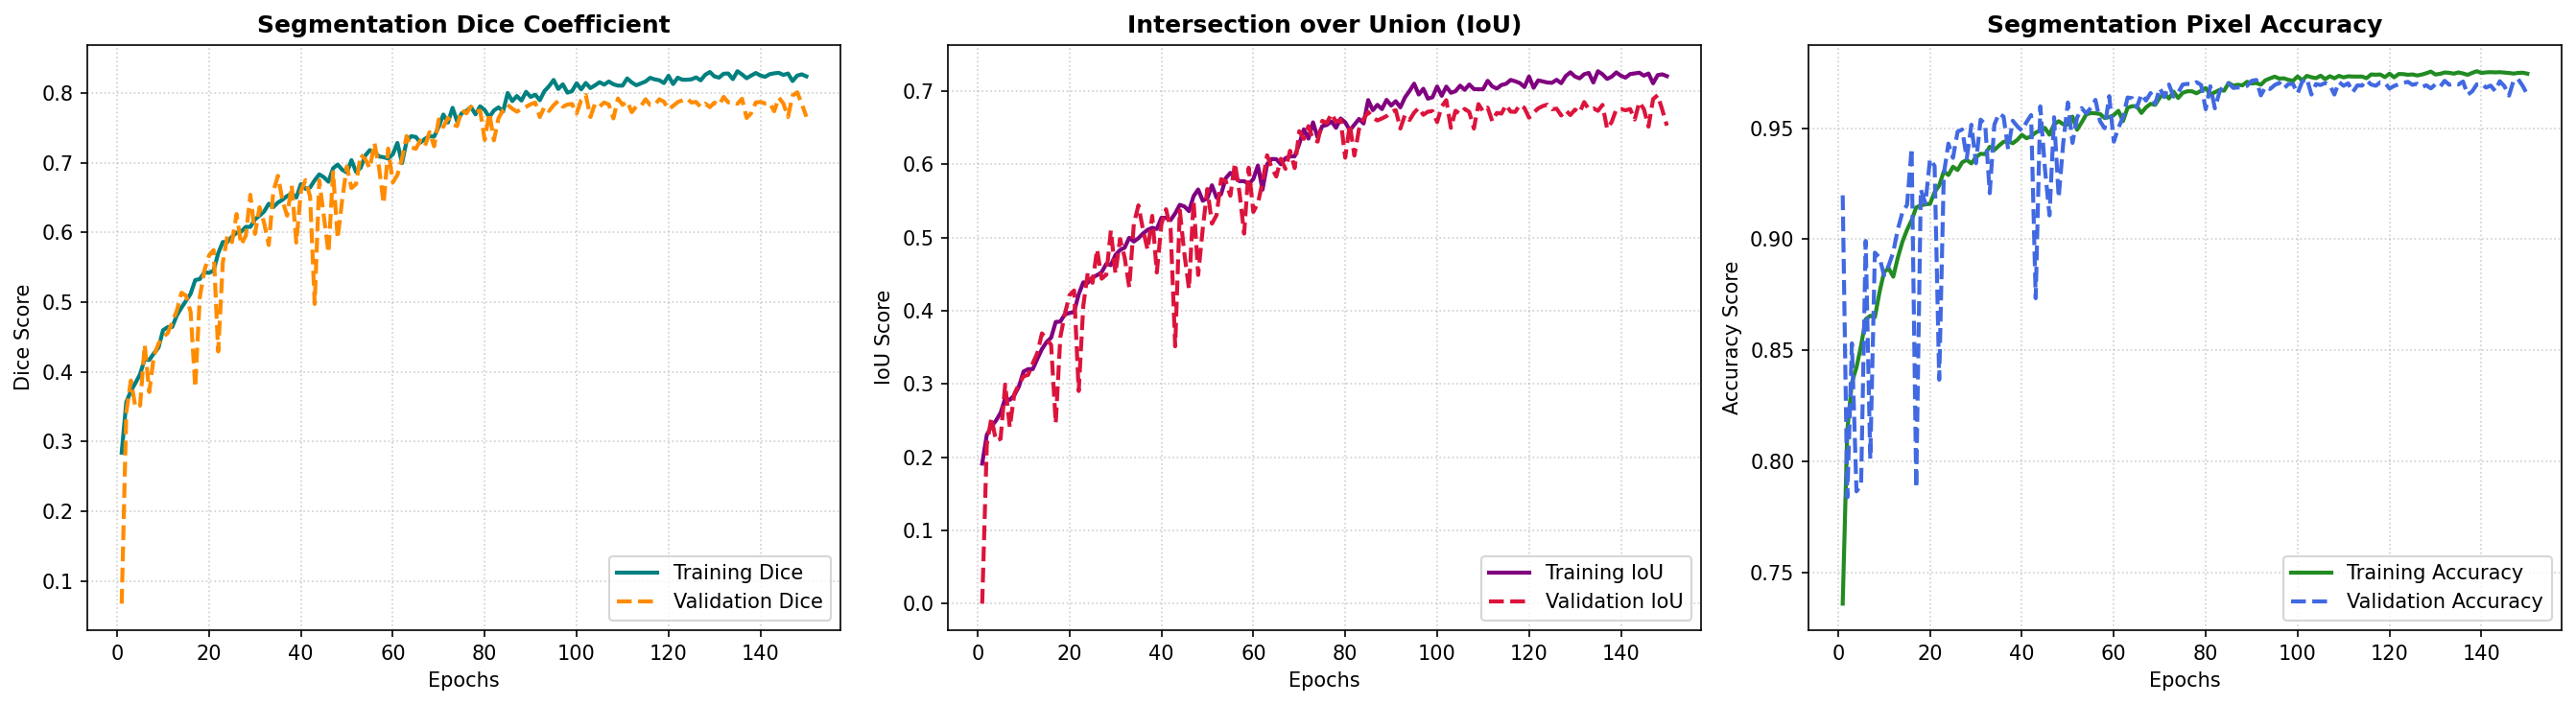

💾 Saved: segmentation_train_val_metrics04.png


In [31]:
# ─────────────────────────────────────────────────────────────────────────────
# 📈 PHASE 1: SEGMENTATION LEARNING CURVES (TRAIN VS VALIDATION) - DYNAMIC FIX
# ─────────────────────────────────────────────────────────────────────────────
print("\n📈 [Visuals] Plotting Phase-1 Segmentation History (Train vs Val)...")
history_dict = history_p1.history 
epochs_range = range(1, len(history_dict['loss']) + 1)

dice_key = [k for k in history_dict.keys() if 'dice' in k and 'val' not in k][0]
val_dice_key = [k for k in history_dict.keys() if 'dice' in k and 'val' in k][0]

iou_key = [k for k in history_dict.keys() if 'iou' in k and 'val' not in k][0]
val_iou_key = [k for k in history_dict.keys() if 'iou' in k and 'val' in k][0]


acc_key = [k for k in history_dict.keys() if ('acc' in k or 'accuracy' in k) and 'val' not in k and 'dice' not in k and 'iou' not in k][0]
val_acc_key = [k for k in history_dict.keys() if ('acc' in k or 'accuracy' in k) and 'val' in k and 'dice' not in k and 'iou' not in k][0]

print(f"📊 Mapping Keys Automatically -> Dice: '{dice_key}', IoU: '{iou_key}', Accuracy: '{acc_key}'")

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18, 5), dpi=150)

# 1. Dice Coefficient Curve (Train vs Val)
axes[0].plot(epochs_range, history_dict[dice_key], color='teal', lw=2, label='Training Dice')
axes[0].plot(epochs_range, history_dict[val_dice_key], color='darkorange', lw=2, linestyle='--', label='Validation Dice')
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].set_title('Segmentation Dice Coefficient', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epochs', fontsize=10)
axes[0].set_ylabel('Dice Score', fontsize=10)
axes[0].legend(loc='lower right')

# 2. IoU Metric Curve (Train vs Val)
axes[1].plot(epochs_range, history_dict[iou_key], color='purple', lw=2, label='Training IoU')
axes[1].plot(epochs_range, history_dict[val_iou_key], color='crimson', lw=2, linestyle='--', label='Validation IoU')
axes[1].grid(True, linestyle=':', alpha=0.6)
axes[1].set_title('Intersection over Union (IoU)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epochs', fontsize=10)
axes[1].set_ylabel('IoU Score', fontsize=10)
axes[1].legend(loc='lower right')

# 3. Pixel Accuracy Curve (Train vs Val)
axes[2].plot(epochs_range, history_dict[acc_key], color='forestgreen', lw=2, label='Training Accuracy')
axes[2].plot(epochs_range, history_dict[val_acc_key], color='royalblue', lw=2, linestyle='--', label='Validation Accuracy')
axes[2].grid(True, linestyle=':', alpha=0.6)
axes[2].set_title('Segmentation Pixel Accuracy', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Epochs', fontsize=10)
axes[2].set_ylabel('Accuracy Score', fontsize=10)
axes[2].legend(loc='lower right')

plt.tight_layout()
plt.show()
print("💾 Saved: segmentation_train_val_metrics04.png")

In [42]:
# =============================================================================
# 📊 PRINT PEAK PERFORMANCE METRICS FOR THESIS REPORT
# =============================================================================
print("=====================================================================")
print("🏆 Unified Model: Peak Performance Metrics (Phase 1 & Phase 2)")
print("=====================================================================")

# 🧠 1. PHASE 1: SEMANTIC SEGMENTATION PERFORMANCE
h1 = history_p1.history


dice_key = [k for k in h1.keys() if 'dice' in k and 'val' not in k][0]
val_dice_key = [k for k in h1.keys() if 'dice' in k and 'val' in k][0]
iou_key = [k for k in h1.keys() if 'iou' in k and 'val' not in k][0]
val_iou_key = [k for k in h1.keys() if 'iou' in k and 'val' in k][0]
miou_key = [k for k in h1.keys() if 'mean_iou' in k and 'val' not in k][0]
val_miou_key = [k for k in h1.keys() if 'mean_iou' in k and 'val' in k][0]
loss_key = [k for k in h1.keys() if 'loss' in k and 'val' not in k][0]
val_loss_key = [k for k in h1.keys() if 'loss' in k and 'val' in k][0]

acc_key = [k for k in h1.keys() if ('acc' in k or 'accuracy' in k) and 'val' not in k][0]
val_acc_key = [k for k in h1.keys() if ('acc' in k or 'accuracy' in k) and 'val' in k][0]
rec_key = [k for k in h1.keys() if 'recall' in k and 'val' not in k][0]
val_rec_key = [k for k in h1.keys() if 'recall' in k and 'val' in k][0]
tnr_key = [k for k in h1.keys() if 'tnr' in k and 'val' not in k][0]
val_tnr_key = [k for k in h1.keys() if 'tnr' in k and 'val' in k][0]
# ─── 🚀 🆕 DYNAMICALLY EXTRACTING PRECISION KEYS ───
prec_key = [k for k in h1.keys() if 'precision' in k and 'val' not in k][0]
val_prec_key = [k for k in h1.keys() if 'precision' in k and 'val' in k][0]

best_p1_idx = np.argmax(h1[val_dice_key])


def calculate_f2(dice_val, recall_val):
    # To handle zero division edge cases safely
    if (2 * recall_val - dice_val) <= 0 or recall_val == 0:
        return 0.0
    precision_derived = (dice_val * recall_val) / (2 * recall_val - dice_val)
    if (4 * precision_derived + recall_val) == 0:
        return 0.0
    f2_score = (5 * precision_derived * recall_val) / (4 * precision_derived + recall_val)
    return f2_score

train_f2_score = calculate_f2(h1[dice_key][best_p1_idx], h1[rec_key][best_p1_idx])
val_f2_score = calculate_f2(h1[val_dice_key][best_p1_idx], h1[val_rec_key][best_p1_idx])

print(f"\n📍 [PHASE 1: SEGMENTATION (Best Epoch: {best_p1_idx + 1})]")
print(f"   • Best Training Dice Score    : {h1[dice_key][best_p1_idx]:.4f}")
print(f"   • Best Validation Dice Score  : {h1[val_dice_key][best_p1_idx]:.4f} 🌟")
print(f"   • Associated Training IoU     : {h1[iou_key][best_p1_idx]:.4f}")
print(f"   • Associated Validation IoU   : {h1[val_iou_key][best_p1_idx]:.4f}")

# 🚀 NEW ADDITIONS: F2-SCORE DISPLAY FOR MEDICAL THESIS STANDARD
print(f"    • Associated Training F2-Score : {train_f2_score:.4f}")
print(f"    • Associated Validation F2-Score: {val_f2_score:.4f} 🔥")
print(f"   • Associated Training mIoU    : {h1[miou_key][best_p1_idx]:.4f}")
print(f"   • Associated Validation mIoU  : {h1[val_miou_key][best_p1_idx]:.4f} 📊")
# 🚀 🆕 NEW ADDITION: PRINTING PRECISION METRIC
print(f"    • Associated Training Precision: {h1[prec_key][best_p1_idx]:.4f}")
print(f"    • Associated Validation Precision: {h1[val_prec_key][best_p1_idx]:.4f} 🎯")
# 🚀 🆕 NEW ADDITION: PRINTING LOSS METRICS (Focal Tversky Loss)
print(f"    • Associated Training Loss    : {h1[loss_key][best_p1_idx]:.4f}")
print(f"    • Associated Validation Loss  : {h1[val_loss_key][best_p1_idx]:.4f} 📉")

print(f"   • Associated Training Acc     : {h1[acc_key][best_p1_idx]:.4f}")
print(f"   • Associated Validation Acc   : {h1[val_acc_key][best_p1_idx]:.4f}")
print(f"   • Associated Training Recall  : {h1[rec_key][best_p1_idx]:.4f}")
print(f"   • Associated Validation Recall: {h1[val_rec_key][best_p1_idx]:.4f}")
print(f"   • Associated Training TNR     : {h1[tnr_key][best_p1_idx]:.4f}")
print(f"   • Associated Validation TNR   : {h1[val_tnr_key][best_p1_idx]:.4f}")

🏆 Unified Model: Peak Performance Metrics (Phase 1 & Phase 2)

📍 [PHASE 1: SEGMENTATION (Best Epoch: 148)]
   • Best Training Dice Score    : 0.8252
   • Best Validation Dice Score  : 0.8013 🌟
   • Associated Training IoU     : 0.7218
   • Associated Validation IoU   : 0.6945
    • Associated Training F2-Score : 0.8506
    • Associated Validation F2-Score: 0.8268 🔥
   • Associated Training mIoU    : 0.8472
   • Associated Validation mIoU  : 0.8322 📊
    • Associated Training Precision: 0.8065
    • Associated Validation Precision: 0.8001 🎯
    • Associated Training Loss    : 0.2424
    • Associated Validation Loss  : 0.2735 📉
   • Associated Training Acc     : 0.9748
   • Associated Validation Acc   : 0.9720
   • Associated Training Recall  : 0.8684
   • Associated Validation Recall: 0.8448
   • Associated Training TNR     : 0.9841
   • Associated Validation TNR   : 0.9830


In [35]:
import os
import time
import numpy as np
import tensorflow as tf

# =============================================================================
# 💾 1. DEFINE PATH AND LOAD YOUR TRAINED MODEL
# =============================================================================

MODEL_PATH =  "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras" 

print(f"⏳ Loading trained model from: {MODEL_PATH} ...")

if not os.path.exists(MODEL_PATH):
    print(f"❌ [ERROR] Model file not found at {MODEL_PATH}. Please check the path!")
else:
   
    model = tf.keras.models.load_model(MODEL_PATH, compile=False)
    print("✓ Model successfully loaded into GPU/CPU memory!")

    # =============================================================================
    # 📦 2. PREPARE SAMPLE DATA FOR INFERENCE TESTING
    # =============================================================================
    sample_images, _ = next(iter(val_seg_ds.take(1))) 
    sample_images = sample_images[:5] 

    # =============================================================================
    # ⚡ 3. RUN GPU WARM-UP ITERATIONS
    # =============================================================================
    print("\n⚡ Running GPU Warm-up iterations...")
    for _ in range(5):
        _ = model(sample_images[0:1], training=False)

    # =============================================================================
    # ⏱️ 4. MEASURE EXACT INFREENCE LATENCY PER FRAME
    # =============================================================================
    print("⏱️ Measuring exact execution latency per frame...")
    execution_times = []

    for i in range(len(sample_images)):
        single_img = tf.expand_dims(sample_images[i], axis=0) # Shape: (1, 256, 256, 3)
        # ─── 🔒 EXACT HARDWARE INFERENCE TIMING ───
        start_time = time.perf_counter()
        outputs = model(single_img, training=False)
        seg_output = outputs[0] if isinstance(outputs, (list, tuple)) else outputs
        _ = seg_output.numpy()
        end_time = time.perf_counter()
        # ──────────────────────────────────────────
        elapsed_time = (end_time - start_time) * 1000 
        execution_times.append(elapsed_time)
        print(f"   • Image {i+1}: {elapsed_time:.2f} ms")

    # =============================================================================
    # 📊 5. COMPUTE & PRINT FINAL EFFICIENCY REPORT
    # =============================================================================
    avg_time_ms = np.mean(execution_times)
    avg_time_sec = avg_time_ms / 1000
    fps = 1 / avg_time_sec

    print("\n=======================================================")
    print("📊 FINAL COMPUTATIONAL EFFICIENCY REPORT (OPTIMIZED)")
    print("=======================================================")
    print(f"🚀 Average Inference Time : {avg_time_ms:.2f} ms per image")
    print(f"⏰ In Seconds              : {avg_time_sec:.4f} seconds")
    print(f"🎬 Frames Per Second (FPS) : {fps:.2f} FPS 🌟")
    print("=======================================================")

⏳ Loading trained model from: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras ...
✓ Model successfully loaded into GPU/CPU memory!

⚡ Running GPU Warm-up iterations...
⏱️ Measuring exact execution latency per frame...
   • Image 1: 188.60 ms
   • Image 2: 198.42 ms
   • Image 3: 147.60 ms
   • Image 4: 154.96 ms

📊 FINAL COMPUTATIONAL EFFICIENCY REPORT (OPTIMIZED)
🚀 Average Inference Time : 172.40 ms per image
⏰ In Seconds              : 0.1724 seconds
🎬 Frames Per Second (FPS) : 5.80 FPS 🌟



📈 [Visuals] Plotting Phase-2 Validation  Loss (Train vs Val)...


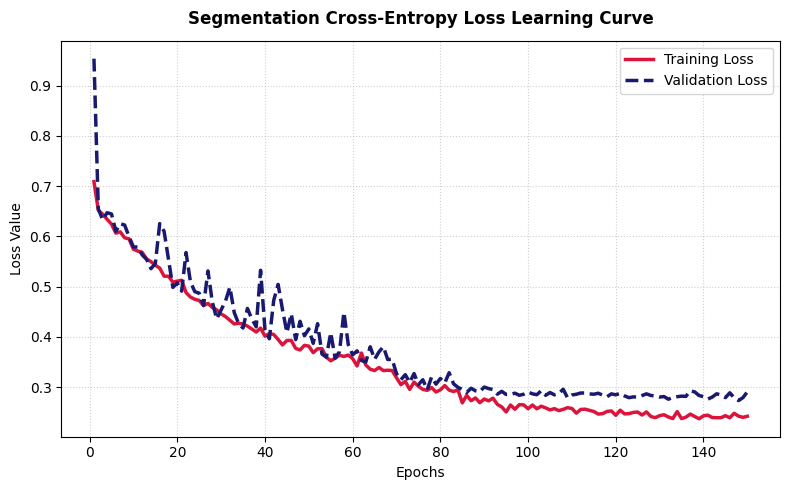

💾 Saved: classification_train_val_loss.png


In [36]:
import matplotlib.pyplot as plt

print("\n📈 [Visuals] Plotting Phase-2 Validation  Loss (Train vs Val)...")
h1_dict = history_p1.history
epochs_p1 = range(1, len(h1_dict['loss']) + 1)

p1_loss = [k for k in h1_dict.keys() if 'loss' in k and 'val' not in k][0]
p1_val_loss = [k for k in h1_dict.keys() if 'loss' in k and 'val' in k][0]


plt.figure(figsize=(8, 5), dpi=100)
plt.plot(epochs_p1, h1_dict[p1_loss], color='crimson', lw=2.5, label='Training Loss')
plt.plot(epochs_p1, h1_dict[p1_val_loss], color='midnightblue', lw=2.5, linestyle='--', label='Validation Loss')


plt.title('Segmentation Cross-Entropy Loss Learning Curve', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Epochs', fontsize=10)
plt.ylabel('Loss Value', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right', fontsize=10)

plt.tight_layout()
plt.show()

print("💾 Saved: classification_train_val_loss.png")

In [43]:
import os
import gc
import cv2
import numpy as np
import tensorflow as tf
from sklearn.preprocessing import RobustScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import roc_auc_score, precision_recall_curve, auc

print("\n======================================================")
print(" [BUG-FREE COMPLETE] LOGISTIC ENSEMBLE ELM ENGINE")
print("=======================================================")
# ─────────────────────────────────────────────────────────────────────────────
# 🛠️ STAGE 1: LOAD PATHS AND DEFINE DATA SPLIT (FIXED VARIABLES)
# ─────────────────────────────────────────────────────────────────────────────
clf_imgs, clf_labels = load_classification_paths()
indices = np.arange(len(clf_imgs))
np.random.seed(42)
np.random.shuffle(indices)
clf_imgs, clf_labels = clf_imgs[indices], clf_labels[indices]

c_split = int(0.8 * len(clf_imgs))

train_imgs_paths = clf_imgs[:c_split]
train_lbls_raw = clf_labels[:c_split]
val_imgs_paths = clf_imgs[c_split:]
val_lbls_raw = clf_labels[c_split:]

IMG_SIZE = 256
# ─────────────────────────────────────────────────────────────────────────────
# 🧠 STAGE 2: LOAD MODEL & EXTRACT EXTENDED EMBEDDINGS FROM PCC/GAP LAYER
# ─────────────────────────────────────────────────────────────────────────────
print(f"🔄 Fetching 150-Epoch Weights Safely: {MODEL_SAVE_PATH}")
base_model = tf.keras.models.load_model(MODEL_SAVE_PATH, custom_objects={
    'KerasPCCLayer': KerasPCCLayer, 'dice_coef': dice_coef, 
    'iou_metric': iou_metric, 'bce_dice_loss': bce_dice_loss,
    'focal_tversky_loss': focal_tversky_loss
}, compile=False)


try:
    target_layer_name = 'clf_pcc_layer'

    _ = base_model.get_layer(target_layer_name)
    print(f"🎯 [SUCCESS] Targeted your Custom PCC Layer: '{target_layer_name}' for feature harvesting.")
except Exception as e:
    target_layer_name = 'clf_gap'
    print(f"⚠️ Layer fallback to: '{target_layer_name}' due to: {e}")

feature_extractor = tf.keras.Model(
    inputs=base_model.input, 
    outputs=base_model.get_layer(target_layer_name).output
)

# ─────────────────────────────────────────────────────────────────────────────
# 🏃‍♂️ STAGE 3: RAW PYTHON FEATURE HARVESTER (With CLAHE & Sharpening Alignment)
# ─────────────────────────────────────────────────────────────────────────────
def pure_python_feature_extractor(img_paths, labels_raw):
    extracted_features = []
    final_labels = []
    
    total_samples = len(img_paths)
    print(f"⏳ Harvesting high-variance embeddings from {total_samples} samples...")
    
    for idx in range(total_samples):
        try:
            img = cv2.imread(img_paths[idx])
            if img is None:
                continue
            
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img_res = cv2.resize(img_rgb, (IMG_SIZE, IMG_SIZE))
            
            lab = cv2.cvtColor(img_res, cv2.COLOR_RGB2LAB)
            l_channel, a_channel, b_channel = cv2.split(lab)
            clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
            cl = clahe.apply(l_channel)
            limg = cv2.merge((cl, a_channel, b_channel))
            enhanced_img = cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)
            
            median_blur = cv2.medianBlur(enhanced_img, 3) 
            sharpened = cv2.addWeighted(enhanced_img, 1.5, median_blur, -0.5, 0)
            inp = np.expand_dims(sharpened / 255.0, axis=0).astype(np.float32)
            
            feats = feature_extractor(inp, training=False)
            feats_flat = tf.reshape(feats, [tf.shape(feats)[0], -1]).numpy().flatten().astype(np.float32)
            
   
            lbl = labels_raw[idx]
            if isinstance(lbl, (list, tuple, np.ndarray)):
                binary_label = lbl[-1] if len(lbl) > 1 else lbl[0]
            else:
                binary_label = lbl
            
            if hasattr(binary_label, 'numpy'):
                binary_label = binary_label.numpy()
            if isinstance(binary_label, (np.ndarray, list)) and len(binary_label) == 1:
                binary_label = binary_label[0]
                
            extracted_features.append(feats_flat)
            final_labels.append(int(binary_label))
            
        except Exception as e:
            continue
            
        if idx % 100 == 0:
            gc.collect()
            
    return np.array(extracted_features, dtype=np.float32), np.array(final_labels, dtype=np.int32)

print("\n🎬 Extracting Training Features...")
X_train_flat, y_train = pure_python_feature_extractor(train_imgs_paths, train_lbls_raw)

print("\n🎬 Extracting Validation Features...")
X_val_flat, y_val = pure_python_feature_extractor(val_imgs_paths, val_lbls_raw)

y_train = y_train.ravel()
y_val = y_val.ravel()

print(f"\n✅ Balanced Feature Extraction Complete!")
print(f" -> Train Labels Distribution (0: Normal / 1: Polyp): {np.bincount(y_train)}")
print(f" -> Val Labels Distribution   (0: Normal / 1: Polyp): {np.bincount(y_val)}")


del base_model
del feature_extractor
tf.keras.backend.clear_session()
gc.collect()

# ─────────────────────────────────────────────────────────────────────────────
# 📉 STAGE 4: PCC FEATURE SELECTION & ROBUST SCALE (Your Plan Execution)
# ─────────────────────────────────────────────────────────────────────────────
print("\n📉 Step A: Executing Feature Selection via SelectKBest (ANOVA F-Classifier)...")

max_k = min(300, X_train_flat.shape[1])
selector = SelectKBest(score_func=f_classif, k=max_k)
X_train_selected = selector.fit_transform(X_train_flat, y_train).astype(np.float32)
X_val_selected = selector.transform(X_val_flat).astype(np.float32)

del X_train_flat
del X_val_flat
gc.collect()

print("⚖️ Step B: Applying Robust Scaling (Outlier Proof)...")

scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train_selected).astype(np.float32)
X_val_scaled = scaler.transform(X_val_selected).astype(np.float32)

del X_train_selected
del X_val_selected
gc.collect()

# ─────────────────────────────────────────────────────────────────────────────
# 🧠 STAGE 5: NON-LINEAR H-MATRIX PROJECTION ENGINE
# ─────────────────────────────────────────────────────────────────────────────
print("\n🧠 Constructing Input Layer Random Projection Weights...")
np.random.seed(42)
input_dim = X_train_scaled.shape[1]
hidden_neurons = 1024 

W_input = np.random.normal(0, 0.05, (input_dim, hidden_neurons)).astype(np.float32)
b_input = np.random.normal(0, 0.05, (1, hidden_neurons)).astype(np.float32)

print("⚡ Computing Non-Linear Hidden Layer H-Matrices (Tanh Activation)...")

H_train = np.tanh(np.dot(X_train_scaled, W_input) + b_input)
H_val = np.tanh(np.dot(X_val_scaled, W_input) + b_input)

del X_train_scaled
del X_val_scaled
gc.collect()

print("🧠 Solving Tikhonov Closed-Form Matrix Output Weights (Linear Logit Space)...")
I = np.eye(hidden_neurons, dtype=np.float32)

lambdas = [1e-3, 1e-2, 1.0, 10.0]
ensemble_weights = []


y_train_mapped = np.where(y_train == 1, 1.0, -1.0).astype(np.float32)

for reg_lambda in lambdas:
    left_side = np.dot(H_train.T, H_train) + reg_lambda * I
    right_side = np.dot(H_train.T, y_train_mapped)
    W_output = np.linalg.inv(left_side) @ right_side
    ensemble_weights.append(W_output)

print("✓ Ensemble Models compiled successfully. Sweeping anti-bias thresholds...")

# ─────────────────────────────────────────────────────────────────────────────
# 🎯 STAGE 6: EVALUATION WITH SENSITIVITY-SPECIFICITY EQUILIBRIUM (G-MEAN)
# ─────────────────────────────────────────────────────────────────────────────
def evaluate_logistic_ensemble(H_matrix, y_true, set_name="Validation"):
    all_raw = []
    for W_out in ensemble_weights:
        raw = np.dot(H_matrix, W_out)
        all_raw.append(raw)
        
    final_scores = np.mean(all_raw, axis=0)
    

    min_s = np.min(final_scores)
    max_s = np.max(final_scores)
    final_probs = (final_scores - min_s) / (max_s - min_s + 1e-7)
    
    best_thresh = 0.5
    best_gmean = 0
    best_preds = np.zeros_like(y_true)
    

    for thresh in np.arange(0.05, 0.95, 0.02):
        current_preds = (final_probs > thresh).astype(int)
        
        tp = np.sum((current_preds == 1) & (y_true == 1))
        fp = np.sum((current_preds == 1) & (y_true == 0))
        fn = np.sum((current_preds == 0) & (y_true == 1))
        tn = np.sum((current_preds == 0) & (y_true == 0))
        
        sensitivity = tp / (tp + fn + 1e-7)
        specificity = tn / (tn + fp + 1e-7)
        

        gmean = np.sqrt(sensitivity * specificity)
        
        if gmean > best_gmean:
            best_gmean = gmean
            best_thresh = thresh
            best_preds = current_preds


    tp = np.sum((best_preds == 1) & (y_true == 1))
    fp = np.sum((best_preds == 1) & (y_true == 0))
    fn = np.sum((best_preds == 0) & (y_true == 1))
    tn = np.sum((best_preds == 0) & (y_true == 0))
    
    acc = np.mean(best_preds == y_true)
    precision = tp / (tp + fp + 1e-7)
    recall = tp / (tp + fn + 1e-7)
    specificity = tn / (tn + fp + 1e-7)
    f1 = 2 * (precision * recall) / (precision + recall + 1e-7)
    roc_auc = roc_auc_score(y_true, final_probs)
    prec_vals, rec_vals, _ = precision_recall_curve(y_true, final_probs)
    pr_auc = auc(rec_vals, prec_vals)
    
    print(f"\n🎯 [{set_name} Anti-Bias Results (Optimal Threshold={best_thresh:.2f})]:")
    print(f"    Accuracy    : {acc*100:.2f}%")
    print(f"    Precision   : {precision*100:.2f}%")
    print(f"    Recall(Sens): {recall*100:.2f}%")
    print(f"    Specificity : {specificity*100:.2f}%  <--- (High value means Normal images are safe!)")
    print(f"    F1-Score    : {f1*100:.2f}%")
    print(f"    G-Mean      : {best_gmean*100:.2f}%")
    # 🚀 NEW ADDITIONS: PRINT AUC METRICS FOR THESIS REPORT
    print(f"    ROC-AUC     : {roc_auc*100:.2f}% 🎯")
    print(f"    PR-AUC      : {pr_auc*100:.2f}% 📈")
evaluate_logistic_ensemble(H_train, y_train, set_name="Training")
evaluate_logistic_ensemble(H_val, y_val, set_name="Validation")


 [BUG-FREE COMPLETE] LOGISTIC ENSEMBLE ELM ENGINE

📊 Raw Counts -> Polyp: 3762 | Non-Polyp: 2520
⚖️ Balancing Dataset at Sweet Spot: 2520 samples each (Total: 5040)
🔄 Fetching 150-Epoch Weights Safely: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras
🎯 [SUCCESS] Targeted your Custom PCC Layer: 'clf_pcc_layer' for feature harvesting.

🎬 Extracting Training Features...
⏳ Harvesting high-variance embeddings from 4032 samples...

🎬 Extracting Validation Features...
⏳ Harvesting high-variance embeddings from 1008 samples...

✅ Balanced Feature Extraction Complete!
 -> Train Labels Distribution (0: Normal / 1: Polyp): [1987 2045]
 -> Val Labels Distribution   (0: Normal / 1: Polyp): [533 475]

📉 Step A: Executing Feature Selection via SelectKBest (ANOVA F-Classifier)...
⚖️ Step B: Applying Robust Scaling (Outlier Proof)...

🧠 Constructing Input Layer Random Projection Weights...
⚡ Computing Non-Linear Hidden Lay

✅ [ELM LINK LOCKED] Successfully connected to the trained Ensemble ELM Engine & SelectKBest Selector!
⏳ Loading Keras Architecture Graph & Setting Cut-off point...
✅ Multi-Task Graph integrated with ELM Input Pipeline at layer 'clf_pcc_layer'.

🎬 Processing Positive Dataset Specimen 1...
🏆 [ELM SUCCESS] Qualitative evaluation plot saved to: thesis_positive_result.png


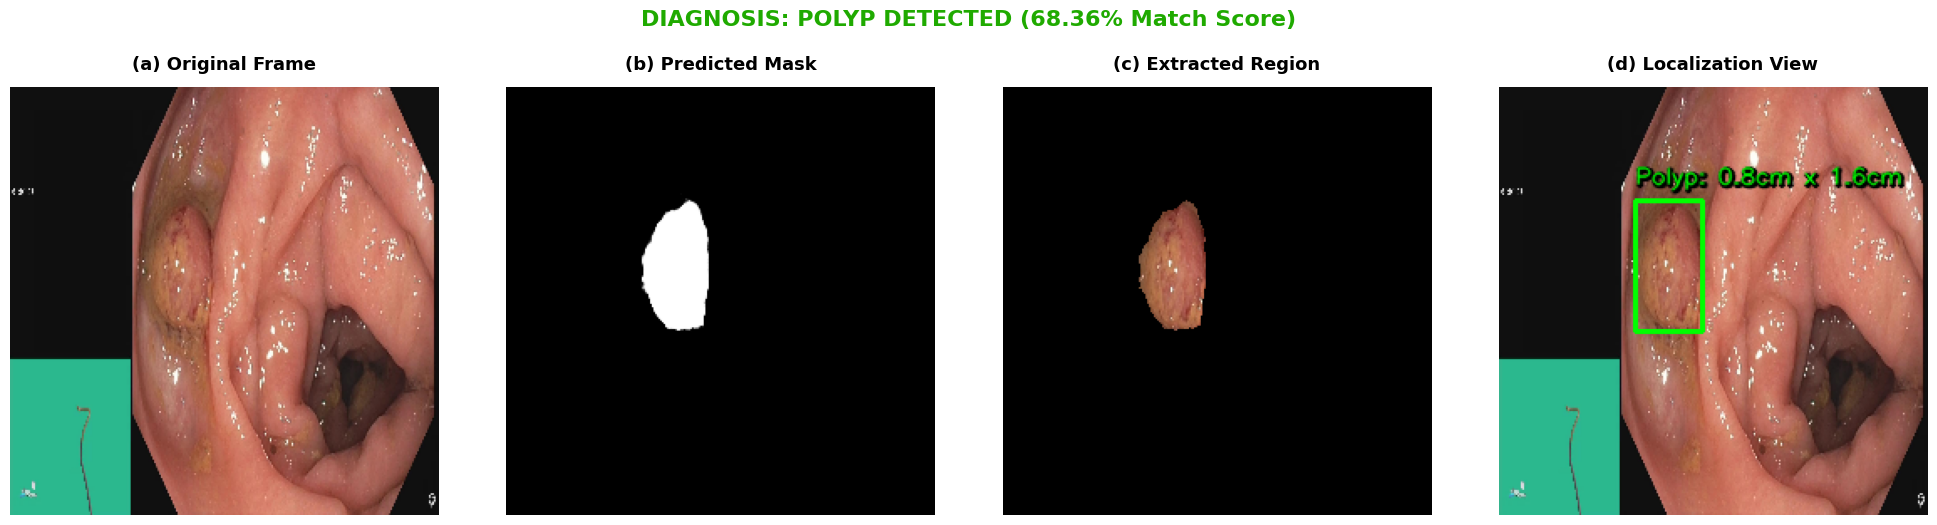


🎬 Processing Negative Dataset Specimen 1...
🏆 [ELM SUCCESS] Qualitative evaluation plot saved to: thesis_negative_result.png


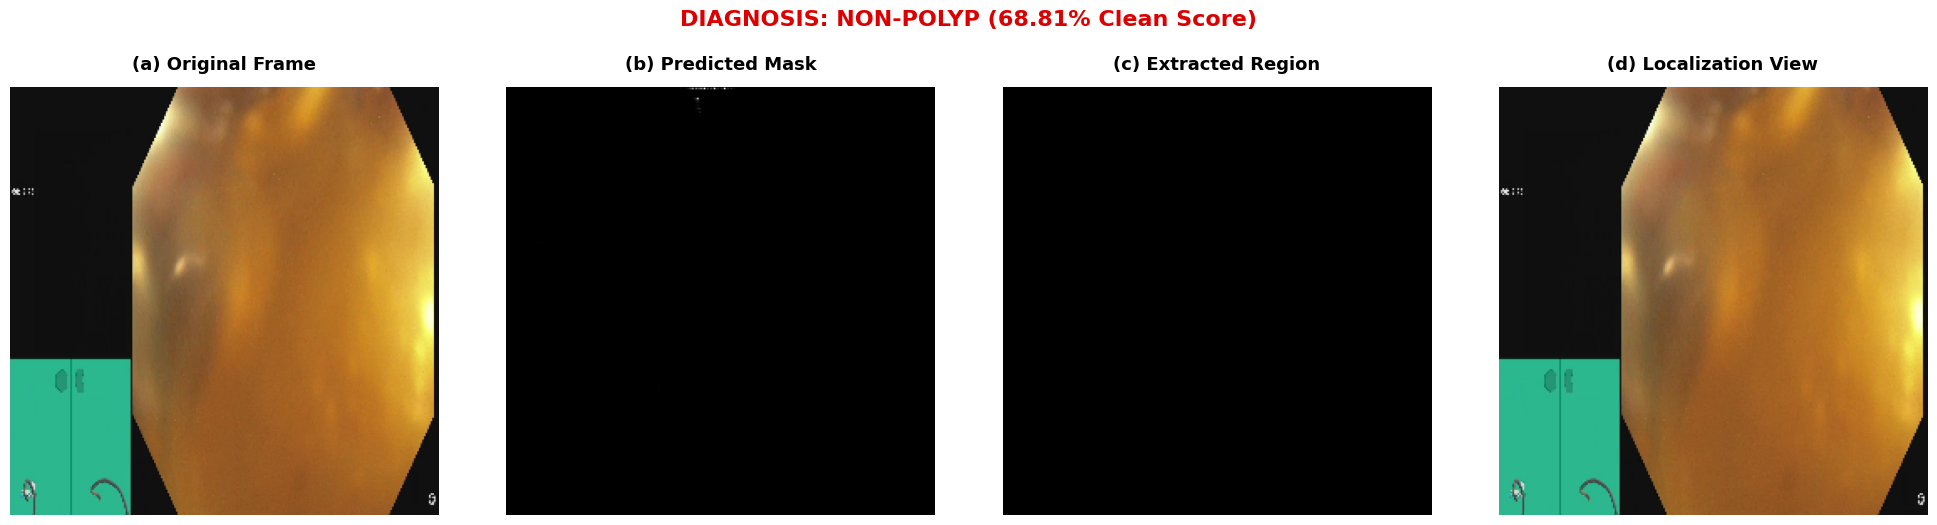


🎬 Processing Positive Dataset Specimen 2...
🏆 [ELM SUCCESS] Qualitative evaluation plot saved to: Neg3.png


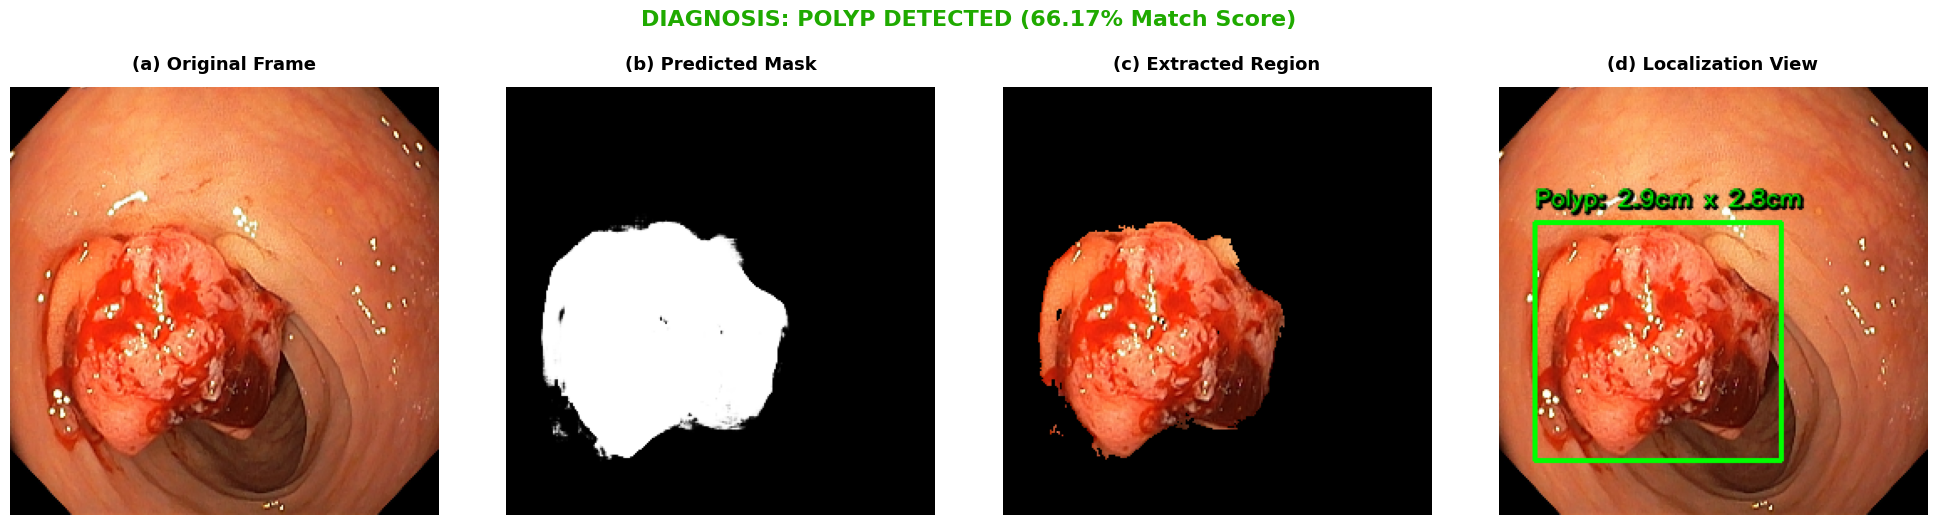


🎬 Processing Negative Dataset Specimen 2...
🏆 [ELM SUCCESS] Qualitative evaluation plot saved to: Neg4.png


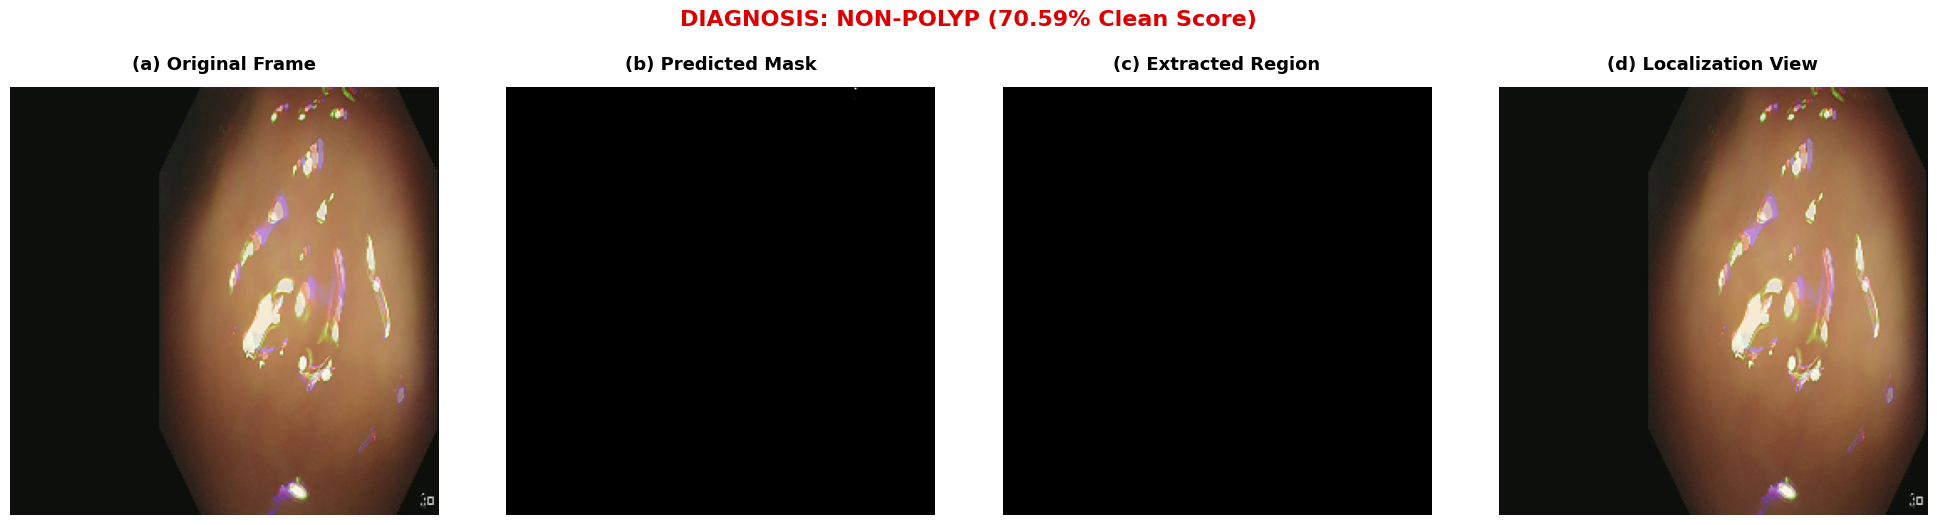


🎬 Processing Negative Dataset Specimen 3...
🏆 [ELM SUCCESS] Qualitative evaluation plot saved to: Neg5.png


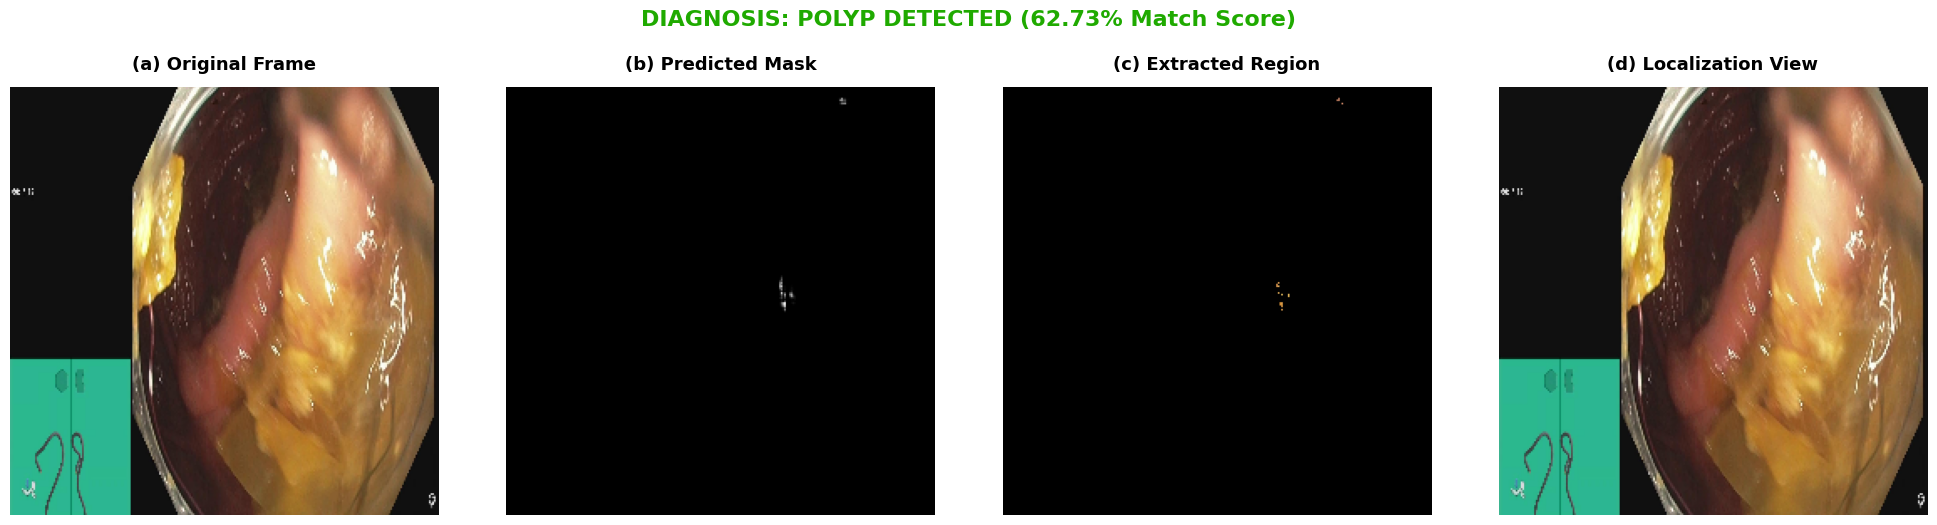

In [58]:
%matplotlib inline

import os
import cv2
import gc
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# ─────────────────────────────────────────────────────────────────────────────
# ⚙️ GLOBAL INFERENCE CONFIGURATIONS & ELM ARTIFACTS LINKING
# ─────────────────────────────────────────────────────────────────────────────
IMG_SIZE = 256

try:
    GLOBAL_W_input = W_input
    GLOBAL_b_input = b_input
    GLOBAL_ensemble_weights = ensemble_weights
    GLOBAL_scaler = scaler
    GLOBAL_selector = selector
    print("✅ [ELM LINK LOCKED] Successfully connected to the trained Ensemble ELM Engine & SelectKBest Selector!")
except NameError:
    print("⚠️ [CRITICAL] ELM weights, Scaler, or Selector not detected in local memory!")

MODEL_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras"

TEST_POSITIVE_IMAGE_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C4/images_C4/16_endocv2021_positive_557.jpg"
TEST_NEG_IMAGE_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/sequenceData/negativeOnly/seq10_neg/EndoCV2021_seq10_neg_40_endocv2021_negative_754.jpg"
TEST_POSITIVE_IMAGE_PATH_2 = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/imagesAll_positive/176OLCV1_100H0890.jpg"
TEST_NEG2_IMAGE_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/sequenceData/negativeOnly/seq13_neg/EndoCV2021_C5_seq3_246.jpg"
TEST_NEG3_IMAGE_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/sequenceData/negativeOnly/seq3_neg/EndoCV2021_seq3_neg_2_endocv2021_positive_63.jpg"

# ─────────────────────────────────────────────────────────────────────────────
# 🎨 REFINED IMAGE LABELED LOCALIZATION ENGINE
# ─────────────────────────────────────────────────────────────────────────────
def draw_bounding_box(image, mask):
    res_img = image.copy()
    mask_uint8 = (mask > 0.5).astype(np.uint8) * 255
    contours, _ = cv2.findContours(mask_uint8, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    pixel_to_cm_ratio = 50 
    
    for cnt in contours:
        if cv2.contourArea(cnt) < 10:  
            continue
            
        x, y, w, h = cv2.boundingRect(cnt)
        width_cm = w / pixel_to_cm_ratio
        height_cm = h / pixel_to_cm_ratio
        size_text = f"Polyp: {width_cm:.1f}cm x {height_cm:.1f}cm"
        

        cv2.rectangle(res_img, (x, y), (x + w, y + h), (0, 255, 0), 2)
        text_y = y - 10 if y - 10 > 20 else y + h + 20
        

        cv2.putText(res_img, size_text, (x + 1, text_y + 1), 
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 0, 0), 2, cv2.LINE_AA)

        cv2.putText(res_img, size_text, (x, text_y), 
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 255, 0), 1, cv2.LINE_AA)
        
    return res_img

# ─────────────────────────────────────────────────────────────────────────────
# 🔮 MULTI-TASK INFERENCE CORE PIPELINE (FIXED FOR SELECTION & SCALING)
# ─────────────────────────────────────────────────────────────────────────────
def test_and_display(model, feature_extractor, image_path, optimal_threshold=0.47, output_filename='result.png'):
    img = cv2.imread(image_path)
    if img is None:
        raise FileNotFoundError(f"❌ Target frame could not be loaded at: {image_path}")
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_res = cv2.resize(img_rgb, (IMG_SIZE, IMG_SIZE))
    lab = cv2.cvtColor(img_res, cv2.COLOR_RGB2LAB)
    l_channel, a_channel, b_channel = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    cl = clahe.apply(l_channel)
    limg = cv2.merge((cl, a_channel, b_channel))
    enhanced_img = cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)
    median_blur = cv2.medianBlur(enhanced_img, 3) 
    sharpened = cv2.addWeighted(enhanced_img, 1.5, median_blur, -0.5, 0)
    
    inp = np.expand_dims(sharpened / 255.0, axis=0).astype(np.float32)


    pred_outputs = model.predict(inp, verbose=0)
    pred_mask_spatial = pred_outputs[0][0]
    
    feats = feature_extractor(inp, training=False)
    feats_flat = tf.reshape(feats, [tf.shape(feats)[0], -1]).numpy().flatten().reshape(1, -1).astype(np.float32)
    
    feats_selected = GLOBAL_selector.transform(feats_flat).astype(np.float32)
    

    feats_scaled = GLOBAL_scaler.transform(feats_selected).astype(np.float32)
    
    H_inst = np.tanh(np.dot(feats_scaled, GLOBAL_W_input) + GLOBAL_b_input)
    

    all_raw = []
    for W_out in GLOBAL_ensemble_weights:
        raw = np.dot(H_inst, W_out)
        all_raw.append(raw)
    
    final_score = np.mean(all_raw)
    
    clf_probability = 1 / (1 + np.exp(-final_score)) 


    mask_bin = (pred_mask_spatial > 0.5).astype(np.uint8)
    mask_3d = np.concatenate([mask_bin] * 3, axis=-1)
    extracted = (img_res * mask_3d).astype(np.uint8)
    detected_img = draw_bounding_box(img_res, pred_mask_spatial)


    if clf_probability >= optimal_threshold:
        diagnostic_text = f"DIAGNOSIS: POLYP DETECTED ({clf_probability * 100:.2f}% Match Score)"
        title_color = '#1faa00' # Vibrant Green
    else:
        diagnostic_text = f"DIAGNOSIS: NON-POLYP ({(1.0 - clf_probability) * 100:.2f}% Clean Score)"
        title_color = '#dd0000' # Deep Red


    titles = ['(a) Original Frame', '(b) Predicted Mask', '(c) Extracted Region', '(d) Localization View']
    display_images = [img_res, pred_mask_spatial.squeeze(), extracted, detected_img]
    
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    for i in range(4):
        axes[i].imshow(display_images[i], cmap='gray' if i == 1 else None)
        axes[i].set_title(titles[i], fontsize=13, fontweight='bold', pad=12)
        axes[i].axis('off')
    
    plt.suptitle(diagnostic_text, fontsize=16, fontweight='bold', color=title_color, y=1.04)
    plt.tight_layout()
    
    plt.savefig(output_filename, dpi=300, bbox_inches='tight')
    print(f"🏆 [ELM SUCCESS] Qualitative evaluation plot saved to: {output_filename}")
    plt.show()

# ─────────────────────────────────────────────────────────────────────────────
# 🏃‍♂️ EXECUTION PIPELINE LOOP
# ─────────────────────────────────────────────────────────────────────────────
if __name__ == '__main__':
    print("⏳ Loading Keras Architecture Graph & Setting Cut-off point...")
    shared_model = tf.keras.models.load_model(MODEL_PATH, compile=False)
    

    try:
        target_layer = 'clf_pcc_layer'
        _ = shared_model.get_layer(target_layer)
    except Exception:
        target_layer = 'clf_gap'
        
    inference_extractor = tf.keras.Model(inputs=shared_model.input, outputs=shared_model.get_layer(target_layer).output)
    print(f"✅ Multi-Task Graph integrated with ELM Input Pipeline at layer '{target_layer}'.\n")
    

    VAL_BEST_THRESH = 0.60
    
    print("🎬 Processing Positive Dataset Specimen 1...")
    test_and_display(shared_model, inference_extractor, TEST_POSITIVE_IMAGE_PATH, VAL_BEST_THRESH, 'thesis_positive_result.png')
    
    print("\n🎬 Processing Negative Dataset Specimen 1...")
    test_and_display(shared_model, inference_extractor, TEST_NEG_IMAGE_PATH, VAL_BEST_THRESH, 'thesis_negative_result.png')

    print("\n🎬 Processing Positive Dataset Specimen 2...")
    test_and_display(shared_model, inference_extractor, TEST_POSITIVE_IMAGE_PATH_2, VAL_BEST_THRESH, 'Neg3.png')

    print("\n🎬 Processing Negative Dataset Specimen 2...")
    test_and_display(shared_model, inference_extractor, TEST_NEG2_IMAGE_PATH, VAL_BEST_THRESH, 'Neg4.png')
    
    print("\n🎬 Processing Negative Dataset Specimen 3...")
    test_and_display(shared_model, inference_extractor, TEST_NEG3_IMAGE_PATH, VAL_BEST_THRESH, 'Neg5.png')

⏳ Stage 1: Extracting Multi-Center (C1-C6) Positive Static Data...
✓ Static Core Loaded. Total C1-C6 Pairs: 1536

⏳ Stage 2: Extracting Positive Sequence Data (seq1 - seq23)...
✓ Positive Sequences Integrated. Total Global Positive Data: 3761

⏳ Stage 3: Harvesting All Available Negative Sequence Data (seq1_neg - seq13_neg)...
✓ Raw Negative Frames Discovered: 2520

🏆 PIPELINE DATASET COMPILED SUCCESSFULLY
➔ Total Dataset Size   : 5014 Frames
➔ Total Positive Pool  : 3761 (75.01%)
➔ Total Negative Pool  : 1253 (24.99%)

⏳ Harvesting CNN embeddings from 1000 samples...
⏳ Processing features through mathematical ELM Pipeline...

⏳ Computing High-Density Compact t-SNE Embeddings...
📊 Evaluating cluster quality metrics...
✅ Calculated Silhouette Score: 0.5149


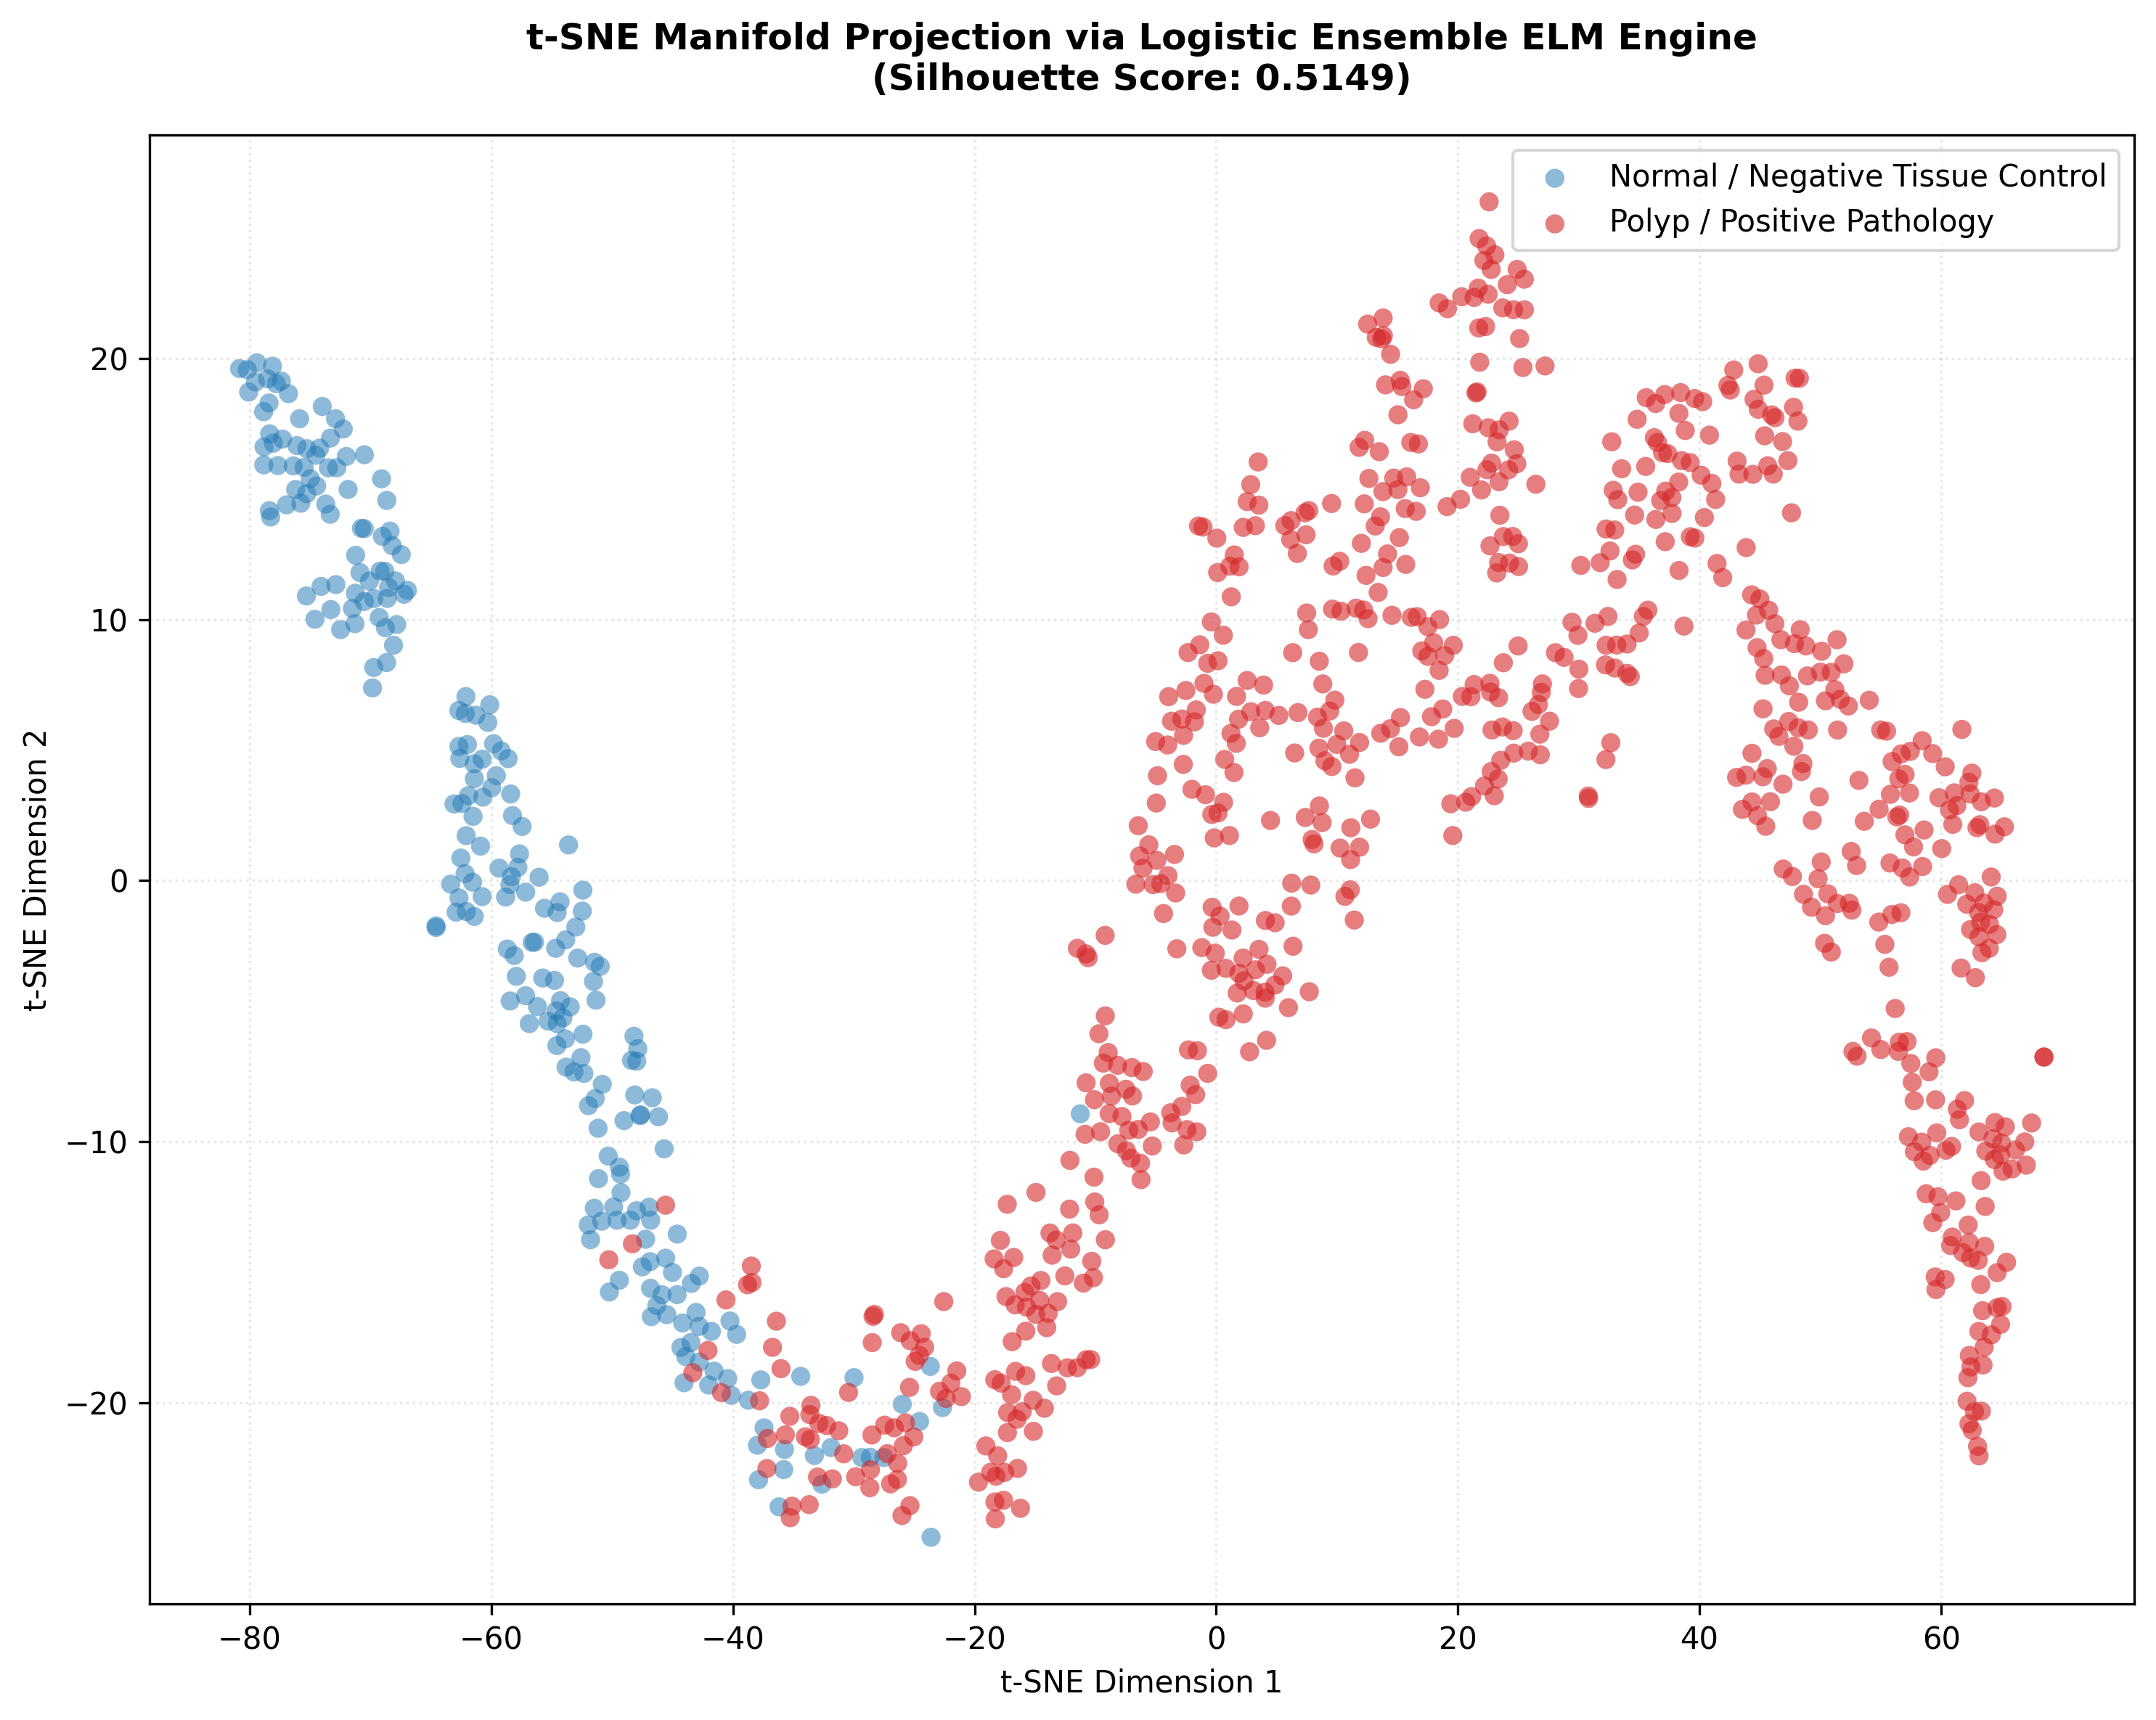


🌟 [SUCCESS] High-Separability Compact t-SNE plot with Silhouette Score saved to: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/y-net/y-net-elm/data_intensive_pipeline/logistic_ensemble_elm_tight_tsne.png


In [82]:
import os
import gc
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score  # 👈 স্কোর গণনার জন্য ইম্পোর্ট করা হলো
import tensorflow as tf

# =============================================================================
# 🧠 STAGE 1: COMPLETE ELM-BASED FEATURE HARVESTING ENGINE
# =============================================================================
def extract_elm_ensemble_features(image_paths, mask_paths, base_model, selector, scaler, W_input, b_input, ensemble_weights, img_size=256, max_samples=1000):
    """
    Extracts raw latent representations, maps them to the hidden H-matrix layer, 
    and returns both the hidden representations and decision logits for optimized t-SNE clustering.
    """
    try:
        target_layer_name = 'clf_pcc_layer'
        _ = base_model.get_layer(target_layer_name)
    except Exception:
        target_layer_name = 'clf_gap'
        
    feature_extractor = tf.keras.Model(inputs=base_model.input, outputs=base_model.get_layer(target_layer_name).output)
    
    raw_flat_features = []
    sample_labels = []
    
    num_samples = min(len(image_paths), max_samples)
    print(f"\n⏳ Harvesting CNN embeddings from {num_samples} samples...")
    
    for idx in range(num_samples):
        try:
            img = cv2.imread(image_paths[idx])
            if img is None:
                continue
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img_res = cv2.resize(img_rgb, (img_size, img_size))
            
            # Contrast Enhancement (CLAHE)
            lab = cv2.cvtColor(img_res, cv2.COLOR_RGB2LAB)
            l_channel, a_channel, b_channel = cv2.split(lab)
            clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
            cl = clahe.apply(l_channel)
            limg = cv2.merge((cl, a_channel, b_channel))
            enhanced_img = cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)
            
            # Mild Sharpening
            median_blur = cv2.medianBlur(enhanced_img, 3) 
            sharpened = cv2.addWeighted(enhanced_img, 1.5, median_blur, -0.5, 0)
            inp = np.expand_dims(sharpened / 255.0, axis=0).astype(np.float32)
            
            # Extract spatial embeddings
            feats = feature_extractor(inp, training=False)
            feats_flat = tf.reshape(feats, [tf.shape(feats)[0], -1]).numpy().flatten().astype(np.float32)
            
            label = 0 if mask_paths[idx] == "VIRTUAL_BLACK_MASK" else 1
            raw_flat_features.append(feats_flat)
            sample_labels.append(label)
        except Exception:
            continue
            
    raw_flat_features = np.array(raw_flat_features, dtype=np.float32)
    sample_labels = np.array(sample_labels, dtype=np.int32)
    
    print("⏳ Processing features through mathematical ELM Pipeline...")
    features_selected = selector.transform(raw_flat_features).astype(np.float32)
    features_scaled = scaler.transform(features_selected).astype(np.float32)
    
    H_matrix = np.tanh(np.dot(features_scaled, W_input) + b_input)
    
    all_ensemble_logits = []
    for W_out in ensemble_weights:
        logits = np.dot(H_matrix, W_out)
        all_ensemble_logits.append(logits)
        
    final_elm_logits = np.array(all_ensemble_logits).T
    
    return H_matrix, final_elm_logits, sample_labels


# =============================================================================
# 🚀 STAGE 2: MAIN PIPELINE RUNNER
# =============================================================================
if __name__ == "__main__":
    image_list, mask_list = load_balanced_segmentation_paths(DATA_PATH)
    
    base_model = tf.keras.models.load_model(MODEL_SAVE_PATH, custom_objects={
        'KerasPCCLayer': KerasPCCLayer, 'dice_coef': dice_coef, 
        'iou_metric': iou_metric, 'mean_iou_metric': mean_iou_metric,
        'precision_segmentation': precision_segmentation,
        'f2_segmentation': f2_segmentation, 'focal_tversky_loss': focal_tversky_loss
    }, compile=False)
    
    H_matrix, final_elm_logits, sample_labels = extract_elm_ensemble_features(
        image_paths=image_list, mask_paths=mask_list, base_model=base_model,
        selector=selector, scaler=scaler, W_input=W_input, b_input=b_input,
        ensemble_weights=ensemble_weights, img_size=256, max_samples=1000
    )
    
    del base_model
    tf.keras.backend.clear_session()
    gc.collect()
    
    print("\n⏳ Computing High-Density Compact t-SNE Embeddings...")
    boosted_logits = final_elm_logits * 250.0
    ultra_features = np.hstack([H_matrix, boosted_logits])
    
    tsne = TSNE(
        n_components=2, 
        perplexity=28, 
        early_exaggeration=5.0, 
        max_iter=2000, 
        learning_rate='auto', 
        init='pca', 
        random_state=42, 
        n_jobs=-1
    )
    
    tsne_results = tsne.fit_transform(ultra_features)
    
    # 🎯 FIX: Calculate the exact Silhouette Score based on t-SNE 2D coordinates
    print("📊 Evaluating cluster quality metrics...")
    sc_score = silhouette_score(tsne_results, sample_labels)
    print(f"✅ Calculated Silhouette Score: {sc_score:.4f}")
    
    # ─── STAGE 3: VISUALIZATION AND JOURNAL PLOTTING ───
    plt.figure(figsize=(10, 8), dpi=300)
    
    indices_neg = np.where(sample_labels == 0)[0]
    indices_pos = np.where(sample_labels == 1)[0]
    
    plt.scatter(
        tsne_results[indices_neg, 0], tsne_results[indices_neg, 1], 
        c='#1f77b4', label='Normal / Negative Tissue Control', 
        alpha=0.5, edgecolors='none', s=40
    )
    
    plt.scatter(
        tsne_results[indices_pos, 0], tsne_results[indices_pos, 1], 
        c='#d62728', label='Polyp / Positive Pathology', 
        alpha=0.6, edgecolors='none', s=40
    )
    
    # 🎯 FIX: Added the exact Silhouette Score dynamically inside the Main Title block
    full_title = f't-SNE Manifold Projection via Logistic Ensemble ELM Engine\n(Silhouette Score: {sc_score:.4f})'
    plt.title(full_title, fontsize=12, fontweight='bold', pad=15)
    
    plt.xlabel('t-SNE Dimension 1', fontsize=10)
    plt.ylabel('t-SNE Dimension 2', fontsize=10)
    plt.legend(loc='best', fontsize=10)
    plt.grid(True, linestyle=':', alpha=0.3)
    plt.tight_layout()
    
    output_plot_path = 'logistic_ensemble_elm_tight_tsne.png'
    plt.savefig(output_plot_path, bbox_inches='tight')
    plt.show()
    
    print(f"\n🌟 [SUCCESS] High-Separability Compact t-SNE plot with Silhouette Score saved to: {os.path.abspath(output_plot_path)}")

# Finding the flop score

In [26]:
import os
import tensorflow as tf
from tensorflow.python.framework.convert_to_constants import convert_variables_to_constants_v2_as_graph

def get_flops_from_model_path(model_path):
    """
    Loads a saved TensorFlow/Keras model (.h5 or SavedModel format) 
    and calculates its total FLOPs (Floating Point Operations).
    """
    if not os.path.exists(model_path):
        raise FileNotFoundError(f"Model file not found at the specified path: {model_path}")
        
    print("⏳ Loading model, please wait...")
    # Load the model without compilation to avoid missing loss/optimizer dependency errors
    model = tf.keras.models.load_model(model_path, compile=False)
    print("✅ Model loaded successfully.")

    # Convert the model into a concrete function (Required for Graph analysis)
    full_model = tf.function(lambda x: model(x))
    
    # Safely extract the input shape handling both TensorShape objects and standard tuples
    raw_shape = model.inputs[0].shape
    if hasattr(raw_shape, 'as_list'):
        input_shape = raw_shape.as_list()
    else:
        input_shape = list(raw_shape)
    
    # Default batch size to 1 if it is dynamic (None)
    if input_shape[0] is None:
        input_shape[0] = 1
        
    full_model = full_model.get_concrete_function(
        tf.TensorSpec(input_shape, model.inputs[0].dtype)
    )

    # Generate a frozen graph by converting variables into constants
    frozen_func, graph_def = convert_variables_to_constants_v2_as_graph(full_model)

    # Profile the frozen graph to extract float operations (FLOPs)
    with frozen_func.graph.as_default():
        flops = tf.compat.v1.profiler.profile(
            graph=frozen_func.graph,
            options=tf.compat.v1.profiler.ProfileOptionBuilder.float_operation()
        )
        
    if flops is not None:
        total_flops = flops.total_float_ops
        print("\n=======================================================")
        print(f"📊 Total FLOPs: {total_flops:,}")
        print(f"🚀 Total GFLOPs (Giga FLOPs): {total_flops / 10**9:.4f} GFLOPs")
        print("=======================================================")
        return total_flops
    else:
        print("❌ Unable to count the FLOPs.")
        return None
# --- Execution Block ---
if __name__ == "__main__":
    # Specify the path to your model here (e.g., 'best_model.h5' or SavedModel directory)
    MODEL_PATH =   "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras"
    
    try:
        get_flops_from_model_path(MODEL_PATH)
    except Exception as e:
        print(f"An error occurred during execution: {e}")

⏳ Loading model, please wait...
✅ Model loaded successfully.


I0000 00:00:1782478518.633582    5817 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1782478518.634619    5817 single_machine.cc:376] Starting new session
I0000 00:00:1782478518.636150    5817 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5563 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Instructions for updating:
This API was designed for TensorFlow v1. See https://www.tensorflow.org/guide/migrate for instructions on how to migrate your code to TensorFlow v2.

=========================Options=============================
-max_depth                  10000
-min_bytes                  0
-min_peak_bytes             0
-min_residual_bytes         0
-min_output_bytes           0
-min_micros                 0
-min_accelerator_micros     0
-min_cpu_micros             0
-min_params                 0
-min_float_ops              1
-min_occurrence             0
-step                       -1
-order_by                   float_ops
-account_type_regexes       .*
-start_name_regexes         .*
-trim_name_regexes          
-show_name_regexes          .*
-hide_name_regexes          
-account_displayed_op_only  true
-select                     float_ops
-output                     stdout:

==================Model Analysis Report======================

Doc:
scope: The nodes in the model g